# US Police Shootings Analysis

The recent past events in the United States with respect to the tragic death of George Floyd by the Minneapolis police has been a dark patch for the US Police History. A wave of anti-racism and anti-police protests and riots swept across the United States.

But I believe, we shouldn't blindly **defund the police** as police plays an important role in maintaining the law and order in the society. So, I wish to analyze the police shootings in the US in order to get more insights about the situation and possible solutions.

[The Washington Post](https://github.com/washingtonpost/data-police-shootings) has tracked the shootings since 2015, reporting more than 5,000 incidents since their tracking began. To analyze this data, I'll use my knowledge of `Python, NumPy, Pandas, Matplotlib and Seaborn` which I've learnt from the course [Data Analysis with Python: Zero to Pandas](zerotopandas.com).

### How to run the code

This is an executable [*Jupyter notebook*](https://jupyter.org) hosted on [Jovian.ml](https://www.jovian.ml), a platform for sharing data science projects. You can run and experiment with the code in a couple of ways: *using free online resources* (recommended) or *on your own computer*.

#### Option 1: Running using free online resources (1-click, recommended)

The easiest way to start executing this notebook is to click the "Run" button at the top of this page, and select "Run on Binder". This will run the notebook on [mybinder.org](https://mybinder.org), a free online service for running Jupyter notebooks. You can also select "Run on Colab" or "Run on Kaggle".


#### Option 2: Running on your computer locally

1. Install Conda by [following these instructions](https://conda.io/projects/conda/en/latest/user-guide/install/index.html). Add Conda binaries to your system `PATH`, so you can use the `conda` command on your terminal.

2. Create a Conda environment and install the required libraries by running these commands on the terminal:

```
conda create -n zerotopandas -y python=3.8 
conda activate zerotopandas
pip install jovian jupyter numpy pandas matplotlib seaborn opendatasets --upgrade
```

3. Press the "Clone" button above to copy the command for downloading the notebook, and run it on the terminal. This will create a new directory and download the notebook. The command will look something like this:

```
jovian clone notebook-owner/notebook-id
```



4. Enter the newly created directory using `cd directory-name` and start the Jupyter notebook.

```
jupyter notebook
```

You can now access Jupyter's web interface by clicking the link that shows up on the terminal or by visiting http://localhost:8888 on your browser. Click on the notebook file (it has a `.ipynb` extension) to open it.


## Downloading the Dataset

Let's first download the dataset using `urlretrieve` from [The Washington Post Github Repository](https://github.com/washingtonpost/data-police-shootings)

In [1]:
dataset_url = 'https://github.com/washingtonpost/data-police-shootings/archive/master.zip' 

In [2]:
from urllib.request import urlretrieve

In [3]:
urlretrieve(dataset_url, 'data-police-shootings')

('data-police-shootings', <http.client.HTTPMessage at 0x107f11940>)

The downloaded file is a zip file. Let's extract all the files from it using `ZipFile` module of python.

In [4]:
# importing required modules 
from zipfile import ZipFile 
  
# specifying the zip file name 
file_name = "data-police-shootings"
  
# opening the zip file in READ mode 
with ZipFile(file_name, 'r') as zip: 
    # printing all the contents of the zip file 
    zip.printdir() 
  
    # extracting all the files 
    print('Extracting all the files now...') 
    zip.extractall() 
    print('Done!')

File Name                                             Modified             Size
data-police-shootings-master/                  2025-06-17 14:54:42            0
data-police-shootings-master/CODE_OF_CONDUCT.md 2025-06-17 14:54:42          544
data-police-shootings-master/LICENSE           2025-06-17 14:54:42        14606
data-police-shootings-master/README.md         2025-06-17 14:54:42         4682
data-police-shootings-master/v1/               2025-06-17 14:54:42            0
data-police-shootings-master/v1/2015README.md  2025-06-17 14:54:42         2259
data-police-shootings-master/v1/README.md      2025-06-17 14:54:42         6380
data-police-shootings-master/v1/fatal-police-shootings-data.csv 2025-06-17 14:54:42       877860
data-police-shootings-master/v2/               2025-06-17 14:54:42            0
data-police-shootings-master/v2/README.md      2025-06-17 14:54:42        12661
data-police-shootings-master/v2/fatal-police-shootings-agencies.csv 2025-06-17 14:54:42       284808
d

Let's retrieve the list of files in the dataset.

In [5]:
data_dir = 'data-police-shootings-master'

In [6]:
import os
os.listdir(data_dir)

['v1', 'CODE_OF_CONDUCT.md', 'LICENSE', 'README.md', 'v2']

It seems like the dataset contains 4 files:
- `LICENSE` - the license information

- `2015README.md` - the 2015 README file containing information about the dataset

- `README.md` - the updated README file

- `fatal-police-shootings-data.csv` - containing various information about the police shootings

Let's load the CSV files using the Pandas library. We'll use the name `raw_df` for the data frame, to indicate that this is unprocessed data which we might clean, filter and modify to prepare a data frame that's ready for analysis.

In [7]:
import pandas as pd

In [8]:
raw_df = pd.read_csv('data-police-shootings-master/v1/fatal-police-shootings-data.csv')

In [9]:
raw_df

,id,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera,longitude,latitude,is_geocoding_exact
0,3,Tim Elliot,2015-01-02,shot,gun,53.0,M,A,Shelton,WA,True,attack,Not fleeing,False,-123.122,47.247,True
1,4,Lewis Lee Lembke,2015-01-02,shot,gun,47.0,M,W,Aloha,OR,False,attack,Not fleeing,False,-122.892,45.487,True
2,5,John Paul Quintero,2015-01-03,shot and Tasered,unarmed,23.0,M,H,Wichita,KS,False,other,Not fleeing,False,-97.281,37.695,True
3,8,Matthew Hoffman,2015-01-04,shot,toy weapon,32.0,M,W,San Francisco,CA,True,attack,Not fleeing,False,-122.422,37.763,True
4,9,Michael Rodriguez,2015-01-04,shot,nail gun,39.0,M,H,Evans,CO,False,attack,Not fleeing,False,-104.692,40.384,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7997,8690,NaN,2022-11-30,shot,vehicle,NaN,M,NaN,Mesa,AZ,False,attack,NaN,False,-111.810,33.401,True
7998,8692,NaN,2022-11-30,shot,knife,NaN,M,NaN,Mariposa County,CA,False,other,NaN,False,-119.986,37.500,True
7999,8694,NaN,2022-12-01,shot,gun,38.0,M,NaN,Tulare,CA,False,attack,NaN,False,-119.326,36.240,True
8000,8695,NaN,2022-12-01,shot,gun,NaN,M,NaN,Topeka,KS,False,other,NaN,False,-95.694,39.032,True


The dataset contains over `5,600` police shooting records from `Jan 2, 2015` to `Oct 4, 2020`.

Let's view the list of columns in the data frame.

In [10]:
raw_df.columns

Index(['id', 'name', 'date', 'manner_of_death', 'armed', 'age', 'gender',
       'race', 'city', 'state', 'signs_of_mental_illness', 'threat_level',
       'flee', 'body_camera', 'longitude', 'latitude', 'is_geocoding_exact'],
      dtype='str')

There are many columns in the dataset with each column containing a specific information about the incidents. We can read the `README.md` file to get more details about the columns and the data in each column. We will analyze these columns later in more detail.

We've now loaded the dataset, and we're ready to move on to the next step of preprocessing & cleaning the data for our analysis.

## Data Preparation and Cleaning

We'll be doing the following:
- Explore the values in rows and columns
- Handle the missing, incorrect and invalid data
- Remove the unnecessary columns or rows which are not required for our analysis
- Change the values or format of data wherever required
- Add new columns if necessary for our analysis

Let's extract a copy of the data from these columns into a new data frame `df`, which we can continue to modify further without affecting the original data frame.

In [11]:
df = raw_df.copy()

In [12]:
df.columns

Index(['id', 'name', 'date', 'manner_of_death', 'armed', 'age', 'gender',
       'race', 'city', 'state', 'signs_of_mental_illness', 'threat_level',
       'flee', 'body_camera', 'longitude', 'latitude', 'is_geocoding_exact'],
      dtype='str')

As we have the columns `state` and `city` for the location information, we don't really need the exact co-ordinates for our analysis here. We also don't need the `id` column. So, let's drop the columns `id, longitude, latitude and is_geocoding_exact` using the `drop` method

In [13]:
df.drop(columns=['id', 'longitude', 'latitude', 'is_geocoding_exact'], inplace=True)

Let's view some basic information about the data frame.

In [14]:
df.shape

(8002, 13)

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8002 entries, 0 to 8001
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   name                     7548 non-null   str    
 1   date                     8002 non-null   str    
 2   manner_of_death          8002 non-null   str    
 3   armed                    7791 non-null   str    
 4   age                      7499 non-null   float64
 5   gender                   7971 non-null   str    
 6   race                     6485 non-null   str    
 7   city                     8002 non-null   str    
 8   state                    8002 non-null   str    
 9   signs_of_mental_illness  8002 non-null   bool   
 10  threat_level             8002 non-null   str    
 11  flee                     7036 non-null   str    
 12  body_camera              8002 non-null   bool   
dtypes: bool(2), float64(1), str(10)
memory usage: 703.4 KB


### Listing and Correcting missing values

In [16]:
df.isnull().sum()

name                        454
date                          0
manner_of_death               0
armed                       211
age                         503
gender                       31
race                       1517
city                          0
state                         0
signs_of_mental_illness       0
threat_level                  0
flee                        966
body_camera                   0
dtype: int64

As the integration point of our discussion will be **Race**, nulls are of no use. Also, there are no other features to predict the race. So, let's remove the data where `race` is `NULL`

In [17]:
df = df.loc[df.race.notnull()]

Let's have a look at missing values again.

In [18]:
df.isnull().sum()

name                        55
date                         0
manner_of_death              0
armed                      200
age                        135
gender                       3
race                         0
city                         0
state                        0
signs_of_mental_illness      0
threat_level                 0
flee                       575
body_camera                  0
dtype: int64

We still have missing values in few other columns. But they donot concern us right now. If required, we'll deal with them later.

Now move on to the column level to see the type of data for each column. By looking at the initial rows, 'name', 'date', 'age', 'gender', 'race', 'city', 'state' are straight-forward. But there seems to be ambiguity with other columns.

In [19]:
# printing the unique values in each column
print(df.manner_of_death.unique())
print(df.armed.unique())
print(df.signs_of_mental_illness.unique())
print(df.threat_level.unique())
print(df.flee.unique())
print(df.body_camera.unique())

<StringArray>
['shot', 'shot and Tasered']
Length: 2, dtype: str
<StringArray>
[               'gun',            'unarmed',         'toy weapon',
           'nail gun',              'knife',                  nan,
             'shovel',            'vehicle',             'hammer',
            'hatchet',
 ...
          'tire iron',             'bottle',    'gun and machete',
     'Airsoft pistol',         'microphone',  'knife and vehicle',
 'machete and hammer',     'ax and machete',          'flare gun',
                'Gun']
Length: 102, dtype: str
[ True False]
<StringArray>
['attack', 'other', 'undetermined']
Length: 3, dtype: str
<StringArray>
['Not fleeing', 'Car', 'Foot', 'Other', nan]
Length: 5, dtype: str
[False  True]


Other columns look fine, except `armed`
- Looks like the values were entered manually
- The words 'unknown weapon', 'undetermined' and 'claimed to be armed' are of same meaning
- So many repetitions of weapons that are similar eg. 'vehicle and gun', 'gun and vehicle'

### Armed Categorization
As we don't have any information to know whether the null values in `armed` are unarmed or armed with some weapon, let's drop them.

In [20]:
df = df.loc[df.armed.notnull()]

Let's normalize `['unknown weapon', 'undetermined', 'claimed to be armed']` to one word `unknown`

In [21]:
# unknowns_list = ['unknown', 'unknown weapon', 'undetermined', 'claimed to be armed']
# df.armed.loc[df.armed.str.contains('|'.join(unknowns_list), case = False)] = 'unknown'

unknowns_list = ['unknown', 'unknown weapon', 'undetermined', 'claimed to be armed']

mask = df['armed'].str.contains('|'.join(unknowns_list), case=False, na=False)

df.loc[mask, 'armed'] = 'unknown'

**Now, let's categorize each of the weapons.**

In [22]:
# The Dictionary
dictionary = {
    'Guns': ['BB gun', 'pellet gun', 'air pistol', 'Airsoft pistol', 'bean-bag gun', 'gun'],
    
    'Blunt Instruments': ['hammer', 'axe', 'ax', 'hatchet', 'crowbar', 'pole', 'rod', 'walking stick', 'stick', 'rock', 'baton', 'shovel',
        'metal object', 'baseball bat', 'bat', 'flagpole', 'metal pole', 'metal stick', 'blunt object', 'metal pipe', 
         'carjack', 'brick', 'garden tool', 'metal rake', 'mace', 'wrench', 'pipe', 'tire iron'],
    
    'Sharp Objects': ['knife', 'bayonet', 'razor', 'blade', 'machete', 'sword', 'chainsaw', 'chain saw' , 'sharp object', 'scissor',
         'scissors','chain saw', 'glass shard', 'samurai sword', 'lawn mower blade', 'box-cutter', 'straight edge razor',
        'beer bottle', 'bottle', 'sharp object','meat cleaver', 'box cutter'],
    
    'Piercing Objects': ['spear', 'pick-axe', 'pick axe', 'pitchfork', 'cordless drill', 'nail gun', 'nailgun', 'pen',
        'crossbow', 'arrow and bow', 'screwdriver', 'ice pick', 'bow and arrow'],
    
    'Other': ['oar', 'chair', 'barstool', 'pepper spray', 'spray', 'wasp spray', 'piece of wood',
        'toy weapon', 'torch', 'flashlight', 'air conditioner', 'hand torch', "contractor's level", 'chain', 'stapler'],
    
    'Hand Tools': ['metal hand tool'],
    
    'Vehicles': ['motorcycle', 'car', 'van', 'wagon', 'bike', 'vehicle'],
    
    'Electrical Devices': ['taser'],
    
    'Explosives': ['fireworks', 'grenade', 'molotov cocktail', 'incendiary device']
}

Mapping each of the weapons to another categorical column i.e `arms_category` using the dictionary we created above.

In [23]:
def categorize_arms(row):
    armed = row['armed'].lower()
    if 'and' in armed.split(' '): #using 'and' as separator to recognize multiple weapons
        row['arms_category'] = 'Multiple'
    elif armed in dictionary.keys():
        row['arms_category'] = armed
    elif armed == 'unknown':
        row['arms_category'] = 'Unknown'
    elif armed == 'unarmed':
        row['arms_category'] = 'Unarmed'
    else:
        for key, value in dictionary.items():
            if armed in value:
                row['arms_category'] = key
    return row

arms_categorized = df
arms_categorized['arms_category'] = None
arms_categorized = arms_categorized.apply(categorize_arms, axis = 'columns')
df = arms_categorized

We have successfully categorized all the weapons and will use this column for future analysis as it provides more concise information. See for yourself!

In [24]:
df.head()

,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera,arms_category
0,Tim Elliot,2015-01-02,shot,gun,53.0,M,A,Shelton,WA,True,attack,Not fleeing,False,Guns
1,Lewis Lee Lembke,2015-01-02,shot,gun,47.0,M,W,Aloha,OR,False,attack,Not fleeing,False,Guns
2,John Paul Quintero,2015-01-03,shot and Tasered,unarmed,23.0,M,H,Wichita,KS,False,other,Not fleeing,False,Unarmed
3,Matthew Hoffman,2015-01-04,shot,toy weapon,32.0,M,W,San Francisco,CA,True,attack,Not fleeing,False,Other
4,Michael Rodriguez,2015-01-04,shot,nail gun,39.0,M,H,Evans,CO,False,attack,Not fleeing,False,Piercing Objects


Races are denoted with a single letter. It may confuse some viewers.
- `A for Asian`
- `B for Black`
- `W for White`
- `H for Hispanic`
- `N for Native`
- `O for Other`

Let's change the letters to full words

In [25]:
def assign_Race(race):
    if race == 'A':
        race = 'Asian'
    elif race == 'B':
        race = 'Black'
    elif race == 'H':
        race = 'Hispanic'
    elif race == 'N':
        race = 'Native'
    elif race == 'O':
        race = 'Other'
    elif race == 'W':
        race = 'White'
    return race

df.loc[:,'race'] = df.race.apply(assign_Race)

In [26]:
df

,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera,arms_category
0,Tim Elliot,2015-01-02,shot,gun,53.0,M,Asian,Shelton,WA,True,attack,Not fleeing,False,Guns
1,Lewis Lee Lembke,2015-01-02,shot,gun,47.0,M,White,Aloha,OR,False,attack,Not fleeing,False,Guns
2,John Paul Quintero,2015-01-03,shot and Tasered,unarmed,23.0,M,Hispanic,Wichita,KS,False,other,Not fleeing,False,Unarmed
3,Matthew Hoffman,2015-01-04,shot,toy weapon,32.0,M,White,San Francisco,CA,True,attack,Not fleeing,False,Other
4,Michael Rodriguez,2015-01-04,shot,nail gun,39.0,M,Hispanic,Evans,CO,False,attack,Not fleeing,False,Piercing Objects
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7977,Cody Allan Smestad,2022-11-23,shot,gun,30.0,M,White,Chandler,AZ,False,other,Foot,True,Guns
7981,Austin Lee Edwards,2022-11-25,shot,gun,28.0,M,White,San Bernardino County,CA,False,attack,Foot,False,Guns
7984,Angela Nuckols,2022-11-25,shot,gun,58.0,F,White,Round Rock,TX,False,other,Car,False,Guns
7987,NaN,2022-11-25,shot,ax,30.0,M,White,McKinney,TX,False,other,Foot,False,Blunt Instruments


As we can see, the index values have not reset. So, let's do it.

In [27]:
df.reset_index(inplace = True)
df.drop(columns=['index'], inplace = True)

In [28]:
df

,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera,arms_category
0,Tim Elliot,2015-01-02,shot,gun,53.0,M,Asian,Shelton,WA,True,attack,Not fleeing,False,Guns
1,Lewis Lee Lembke,2015-01-02,shot,gun,47.0,M,White,Aloha,OR,False,attack,Not fleeing,False,Guns
2,John Paul Quintero,2015-01-03,shot and Tasered,unarmed,23.0,M,Hispanic,Wichita,KS,False,other,Not fleeing,False,Unarmed
3,Matthew Hoffman,2015-01-04,shot,toy weapon,32.0,M,White,San Francisco,CA,True,attack,Not fleeing,False,Other
4,Michael Rodriguez,2015-01-04,shot,nail gun,39.0,M,Hispanic,Evans,CO,False,attack,Not fleeing,False,Piercing Objects
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6280,Cody Allan Smestad,2022-11-23,shot,gun,30.0,M,White,Chandler,AZ,False,other,Foot,True,Guns
6281,Austin Lee Edwards,2022-11-25,shot,gun,28.0,M,White,San Bernardino County,CA,False,attack,Foot,False,Guns
6282,Angela Nuckols,2022-11-25,shot,gun,58.0,F,White,Round Rock,TX,False,other,Car,False,Guns
6283,NaN,2022-11-25,shot,ax,30.0,M,White,McKinney,TX,False,other,Foot,False,Blunt Instruments


**All done! Our data is a lot better than it was!**

We've now cleaned up and prepared the dataset for analysis. Let's take a look at sample of rows from the data frame.

In [46]:
df.sample(10)

,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera,arms_category,year
1353,Randy Blecher,2016-06-24,shot,gun,50.0,M,White,Farmington,AR,False,attack,Not fleeing,False,Guns,2016
1930,David Lee Montano,2017-02-23,shot,gun,33.0,M,Hispanic,Newton,KS,False,attack,Not fleeing,False,Guns,2017
832,Somer Speer,2015-11-25,shot,gun,37.0,F,White,Ozark,MO,False,attack,Not fleeing,False,Guns,2015
2233,Edward Taylor,2017-07-09,shot,gun,54.0,M,Black,Akron,OH,False,attack,Not fleeing,False,Guns,2017
1502,Kelley Brandon Forte,2016-08-22,shot,knife,34.0,M,Black,Hamilton,OH,False,attack,Not fleeing,False,Sharp Objects,2016
5299,Joshua Van Machado,2021-01-13,shot,gun,43.0,M,White,Visalia,CA,False,attack,Not fleeing,False,Guns,2021
34,Scott Hall,2015-01-16,shot,gun,41.0,M,White,Mabank,TX,False,attack,Car,False,Guns,2015
5854,Stephanie Wilson,2022-01-04,shot,gun,28.0,F,Black,Bahama,NC,False,attack,NaN,False,Guns,2022
4659,Robert Musser,2020-04-28,shot,gun,32.0,M,White,Buckeye,AZ,False,attack,Car,False,Guns,2020
1745,Earl Labon Eubanks,2016-12-13,shot and Tasered,gun,32.0,M,Black,Hampton,GA,True,other,Not fleeing,False,Guns,2016


## Exploratory Analysis and Visualization

Before we can ask relevant questions about the shootings, it would help to understand the various columns, distributions of their values and relationship between them. In order to achieve this, we will analyze and visualize the data.

Let's begin by importing`matplotlib.pyplot` and `seaborn`.

In [47]:
import numpy as np
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

sns.set_style('darkgrid')
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.figsize'] = (9, 5)
matplotlib.rcParams['figure.facecolor'] = '#00000000'

In [48]:
df.head()

,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera,arms_category,year
0,Tim Elliot,2015-01-02,shot,gun,53.0,M,Asian,Shelton,WA,True,attack,Not fleeing,False,Guns,2015
1,Lewis Lee Lembke,2015-01-02,shot,gun,47.0,M,White,Aloha,OR,False,attack,Not fleeing,False,Guns,2015
2,John Paul Quintero,2015-01-03,shot and Tasered,unarmed,23.0,M,Hispanic,Wichita,KS,False,other,Not fleeing,False,Unarmed,2015
3,Matthew Hoffman,2015-01-04,shot,toy weapon,32.0,M,White,San Francisco,CA,True,attack,Not fleeing,False,Other,2015
4,Michael Rodriguez,2015-01-04,shot,nail gun,39.0,M,Hispanic,Evans,CO,False,attack,Not fleeing,False,Piercing Objects,2015


In [49]:
df.describe()

,date,age,year
count,6285,6152.000000,6285.00000
mean,2018-08-12 22:25:22.482100,36.890930,2018.13922
min,2015-01-02 00:00:00,6.000000,2015.00000
25%,2016-09-20 00:00:00,27.000000,2016.00000
50%,2018-07-24 00:00:00,35.000000,2018.00000
75%,2020-05-15 00:00:00,45.000000,2020.00000
max,2022-11-27 00:00:00,91.000000,2022.00000
std,NaN,12.683982,2.15264


`age` is the only numeric column in the dataset.
- The average age of the people who were shot is 36.73
- The standard deviation in age is 12.8
- At least a kid aged 6 and a person aged 91 have been shot which doesn't sound right.

### Race
Race is the major point of any discussion regarding the police shootings in US. So, first of all, let's look at the race of the people who were shot, and plot a bar graph.

In [50]:
df.race.unique()

<StringArray>
['Asian', 'White', 'Hispanic', 'Black', 'Other', 'Native']
Length: 6, dtype: str

We can get the count of the people of each race using the `value_counts` method.

In [51]:
race_counts = df.race.value_counts()
race_counts

race
White       3204
Black       1708
Hispanic    1126
Asian        124
Native       104
Other         19
Name: count, dtype: int64

We can visualize this information using a bar chart.

<Axes: title={'center': 'Race of people shot'}, xlabel='race'>

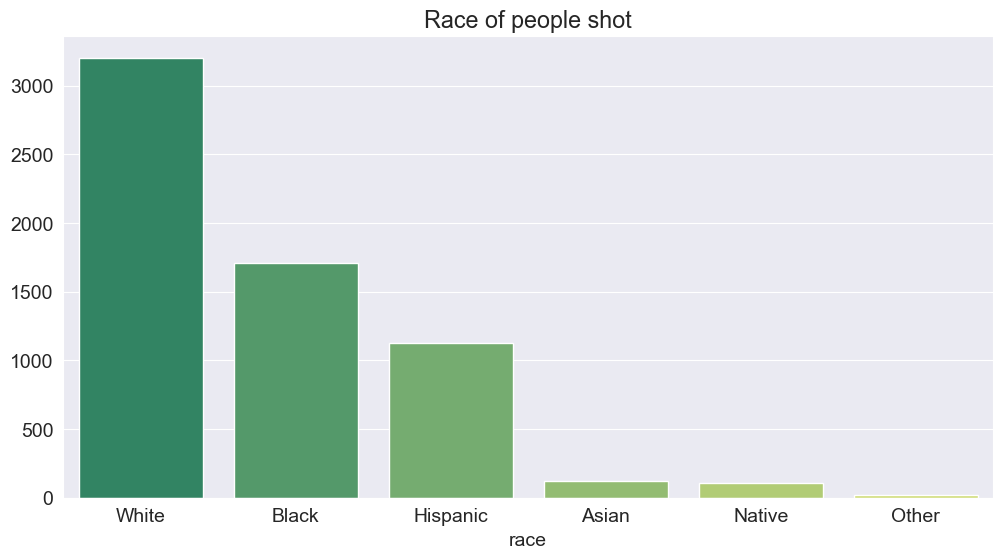

In [55]:
# plt.figure(figsize=(12,6))
# plt.title('Race of people shot')
# sns.barplot(x=race_counts.index, y=race_counts, palette='summer');

plt.figure(figsize=(12,6))
plt.title('Race of people shot')

sns.barplot(
    x=race_counts.index,
    y=race_counts.values,
    hue=race_counts.index,
    palette='summer',
    legend=False
)

More than half of the people shot were White, followed by Black and Hispanic. This is contrary to the popular belief and the media hype that the police target and kill the Black people disproportionately because of racism. We will be exploring this topic further later in our analysis.

### Gender
Let's look at the distribution of the victims for the Gender.

In [56]:
gender_counts = df.gender.value_counts()
gender_counts

gender
M    5985
F     297
Name: count, dtype: int64

A pie chart would be a good way to visualize the distribution.

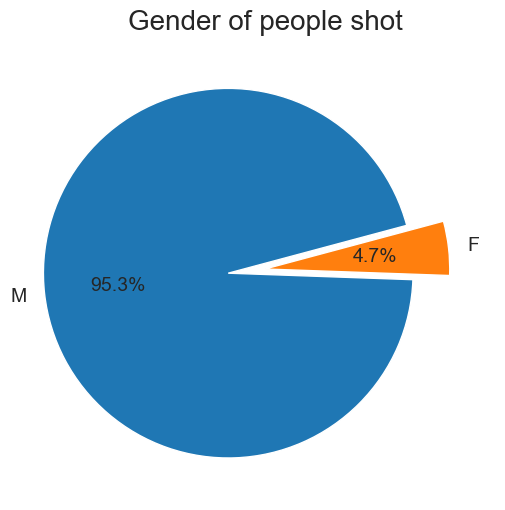

In [57]:
plt.figure(figsize=(12,6))
plt.title('Gender of people shot', size=20)
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', explode=(0.2,0), startangle=15);

F:M ratio of getting shot is **1 Female for every 19 Males**. This is expected as females commit less crimes comparative to males.

### Armed
It's important to see the distribution of the arms used by the victims. Were most of the victims armed or unarmed? Let's plot the top 10 arms used by the victims.

In [58]:
armed_counts = df.armed.value_counts().head(10)
armed_counts

armed
gun           3700
knife          936
unarmed        431
unknown        286
toy weapon     221
vehicle        213
machete         53
Taser           32
ax              25
sword           23
Name: count, dtype: int64

We can use a bar plot to visualize this information.

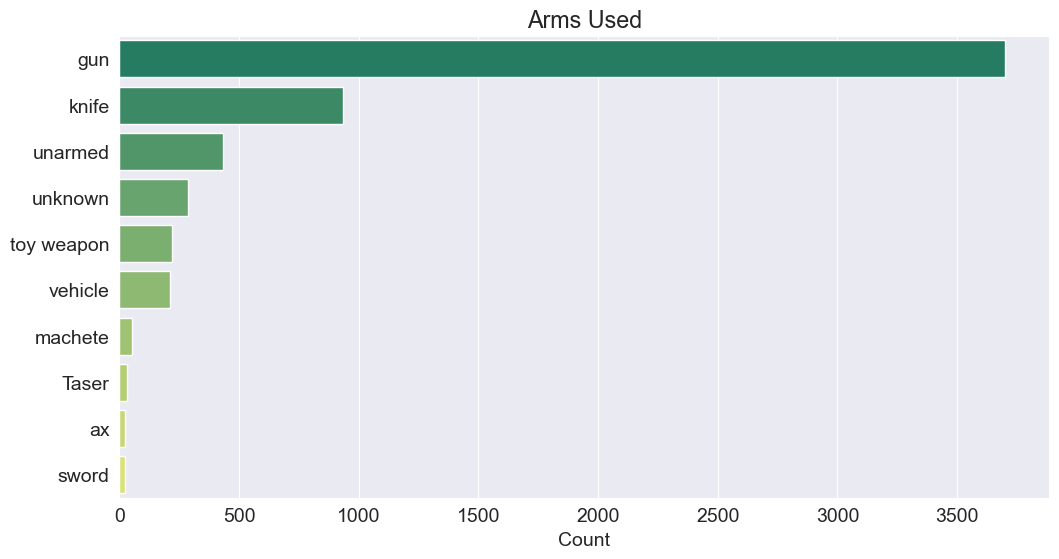

In [62]:
plt.figure(figsize=(12,6))
# sns.barplot(x=armed_counts, y=armed_counts.index, palette='summer')

sns.barplot(
    x=armed_counts.values,
    y=armed_counts.index,
    hue=armed_counts.index,
    palette='summer',
    legend=False
)

plt.title('Arms Used')
plt.ylabel(None)
plt.xlabel('Count');

We can clearly see that vast majority of the people had gun. It was followed by knife and unarmed. A significant number of people were unarmed. Unarmed doesn't necessarily mean not dangerous, but still let's note that unarmed people were also killed.

### Yearwise Killings
It would be useful to study the killings on a year-by-year basis. The `date` column might come in handy here, as Pandas provides many utilities for working with dates.

In [63]:
df.date.head()

0   2015-01-02
1   2015-01-02
2   2015-01-03
3   2015-01-04
4   2015-01-04
Name: date, dtype: datetime64[us]

The data type of date is currently `object`, so Pandas doesn't know that this column is a date. We can convert it into a `datetime` column using the `pd.to_datetime` method.

In [64]:
df.date = pd.to_datetime(df.date)

In [65]:
df.date.head()

0   2015-01-02
1   2015-01-02
2   2015-01-03
3   2015-01-04
4   2015-01-04
Name: date, dtype: datetime64[us]

You can see that it now has the datatype `datetime64`. We can now extract the year into a separate column, using the `DatetimeIndex` class.

In [66]:
df['year'] = pd.DatetimeIndex(df.date).year

In [67]:
df.head()

,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera,arms_category,year
0,Tim Elliot,2015-01-02,shot,gun,53.0,M,Asian,Shelton,WA,True,attack,Not fleeing,False,Guns,2015
1,Lewis Lee Lembke,2015-01-02,shot,gun,47.0,M,White,Aloha,OR,False,attack,Not fleeing,False,Guns,2015
2,John Paul Quintero,2015-01-03,shot and Tasered,unarmed,23.0,M,Hispanic,Wichita,KS,False,other,Not fleeing,False,Unarmed,2015
3,Matthew Hoffman,2015-01-04,shot,toy weapon,32.0,M,White,San Francisco,CA,True,attack,Not fleeing,False,Other,2015
4,Michael Rodriguez,2015-01-04,shot,nail gun,39.0,M,Hispanic,Evans,CO,False,attack,Not fleeing,False,Piercing Objects,2015


As you can see, now we have a new column for the year. Now, let's see the number of killings in each year.

As we want to sort the data according to year instead of count this time, we need to convert the `Series` into a `DataFrame` using `to_frame` method and reset the indices using `reset_index` method. We then, change the column names using `rename` method and sort the values as per the year using `sort_values` method.

In [69]:
# year_counts = df.year.value_counts().to_frame().reset_index().rename(columns={'index':'year', 'year':'count'}).sort_values(by='year')

year_counts = (
    df['year']
      .value_counts()
      .rename_axis('year')
      .reset_index(name='count')
      .sort_values(by='year')
)

In [70]:
year_counts

,year,count
0,2015,923
4,2016,850
5,2017,832
3,2018,877
2,2019,885
1,2020,898
6,2021,585
7,2022,435


We can visualize this information using a line chart.

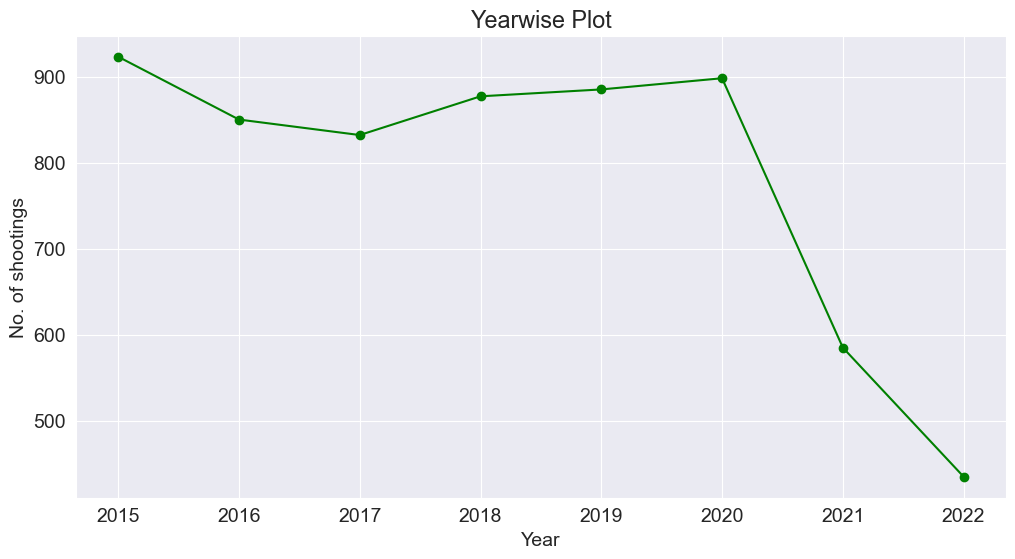

In [71]:
plt.figure(figsize=(12,6))
plt.title('Yearwise Plot')

plt.xlabel('Year')
plt.ylabel('No. of shootings')

plt.plot(year_counts['year'], year_counts['count'], 'o-g');

We can get the average number of killings per year using `mean` method.
We exclude the year 2020 in our calculation as it's still ongoing.

In [72]:
year_counts = year_counts[year_counts.year != 2020]
year_counts['count'].mean()

np.float64(769.5714285714286)

**Observation:**
- After the drop in counts from the year 2015 to 2016, the count of the people shot revolves around 850.
- It has an average of 864 per year. More than 850 people are killed every year.
- The data in the year 2020 is till September, maybe that is why we can see a sudden drop after 2019. Also, the ongoing protests against police might have made the cops avoid shooting.

### Monthwise Killings
Let's now see the number of killings on a month-by-month basis.

In [73]:
# Extracting the months info into separate columns
df['month'] = df['date'].dt.strftime('%B')
df['month_num'] = pd.DatetimeIndex(df.date).month

In [74]:
df.head()

,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera,arms_category,year,month,month_num
0,Tim Elliot,2015-01-02,shot,gun,53.0,M,Asian,Shelton,WA,True,attack,Not fleeing,False,Guns,2015,January,1
1,Lewis Lee Lembke,2015-01-02,shot,gun,47.0,M,White,Aloha,OR,False,attack,Not fleeing,False,Guns,2015,January,1
2,John Paul Quintero,2015-01-03,shot and Tasered,unarmed,23.0,M,Hispanic,Wichita,KS,False,other,Not fleeing,False,Unarmed,2015,January,1
3,Matthew Hoffman,2015-01-04,shot,toy weapon,32.0,M,White,San Francisco,CA,True,attack,Not fleeing,False,Other,2015,January,1
4,Michael Rodriguez,2015-01-04,shot,nail gun,39.0,M,Hispanic,Evans,CO,False,attack,Not fleeing,False,Piercing Objects,2015,January,1


We now have two new columns, one for the month name and the other for the month number.

We make a new dataFrame `month_df` to study the number of shootings in each month of each year.

In [75]:
month_df = df[['year', 'month', 'month_num']]
month_df

,year,month,month_num
0,2015,January,1
1,2015,January,1
2,2015,January,1
3,2015,January,1
4,2015,January,1
...,...,...,...
6280,2022,November,11
6281,2022,November,11
6282,2022,November,11
6283,2022,November,11


We need to create a new dataframe using `groupby` function to group year and month together and aggregate them as per their count.

In [76]:
month_group = month_df.groupby(['year', 'month'], as_index=False).count().rename(columns={'month_num':'count'})
month_group

,year,month,count
0,2015,April,80
1,2015,August,86
2,2015,December,80
3,2015,February,74
4,2015,January,69
...,...,...,...
90,2022,March,43
91,2022,May,44
92,2022,November,40
93,2022,October,46


As you can see the data is arranged in lexicographical order of month names. But we need to sort the months chronologically. So, we use `Categorical` method to categorize the months and sort it as per the categories.

In [77]:
# Sorting the month names
months = ["January", "February", "March", "April", "May", "June", 
          "July", "August", "September", "October", "November", "December"]
month_group['month'] = pd.Categorical(month_group['month'], categories=months, ordered=True)
month_group.sort_values(by = 'month')

,year,month,count
52,2019,January,82
87,2022,January,35
40,2018,January,90
76,2021,January,68
28,2017,January,86
...,...,...,...
62,2020,December,73
38,2018,December,65
74,2021,December,31
14,2016,December,55


In [78]:
avg_per_month = month_group['count'].sum() / (12*6 - 3)
print('Avg death count per month is {}'.format(avg_per_month))

Avg death count per month is 91.08695652173913


We use the `pivot` method to reshape the dataframe in the form of a 2D matrix.

In [80]:
# month_group = month_group.pivot('month', 'year', 'count')
month_group = month_group.pivot(
    index='month',
    columns='year',
    values='count'
)
month_group

year,2015,2016,2017,2018,2019,2020,2021,2022
month,,,,,,,,
January,69.0,77.0,86.0,90.0,82.0,86.0,68.0,35.0
February,74.0,78.0,89.0,69.0,69.0,68.0,79.0,41.0
March,86.0,86.0,65.0,94.0,77.0,76.0,71.0,43.0
April,80.0,65.0,55.0,86.0,66.0,70.0,52.0,39.0
May,65.0,67.0,61.0,68.0,65.0,96.0,49.0,44.0
June,62.0,82.0,74.0,70.0,79.0,75.0,68.0,44.0
July,97.0,68.0,86.0,82.0,71.0,58.0,41.0,33.0
August,86.0,75.0,75.0,70.0,67.0,80.0,28.0,32.0
September,79.0,68.0,61.0,52.0,61.0,57.0,33.0,38.0


It is best to use a `heatmap` to visualize this type of data.

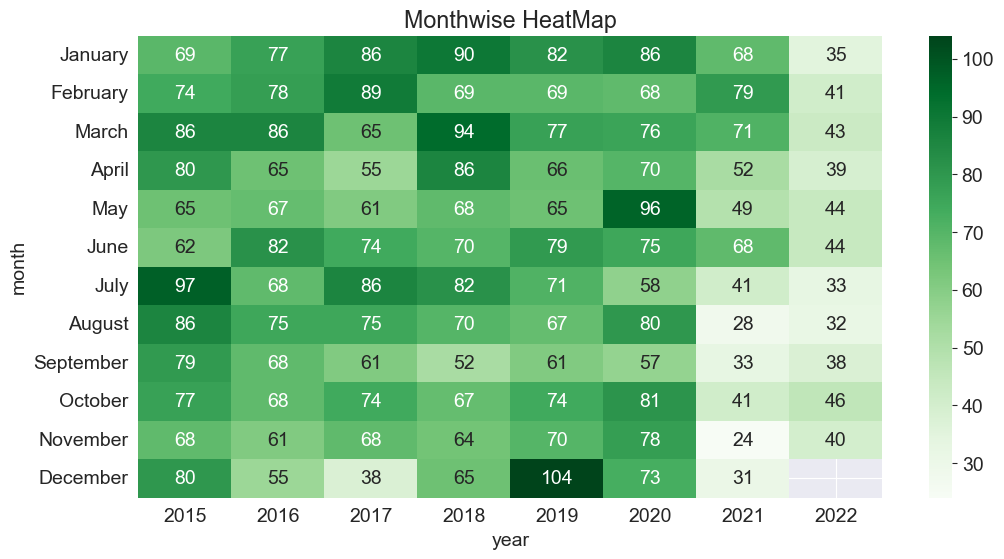

In [81]:
plt.figure(figsize=(12,6))
plt.title("Monthwise HeatMap")
sns.heatmap(month_group, fmt="g", annot=True, cmap="Greens");

**Observation:**
- On average, about 70 people are shot each month.
- The number of shootings in 2020 dropped after May probably as a consequence of the death of George Floyd and the protests.
- But it increased again in August. I read a few articles that the protests turned more violent, which might have been the cause. [Events from August 2020](https://www.infoplease.com/august-2020-current-events-us-news)
- We don't any correlation between the months and the count of shootings over the years 2015 to 2020.

## Asking and Answering Questions

We've already gained several insights about the different columns and the distribution of shootings over years and months. Let's ask some specific questions, and try to answer them using data frame operations and interesting visualizations.

#### Q1: How much of a factor is race in the police shootings?

To answer this, let's first look at the percentage of people killed based on race.

In [82]:
race_pct = df.race.value_counts() * 100 / df.race.count()
race_pct

race
White       50.978520
Black       27.175815
Hispanic    17.915672
Asian        1.972951
Native       1.654733
Other        0.302307
Name: count, dtype: float64

We can visualize this information using a barplot.

/var/folders/sp/8dqfb3vn0bq_mrwp93cz6bjw0000gn/T/ipykernel_36057/942898187.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=race_pct, y=race_pct.index, palette='summer')


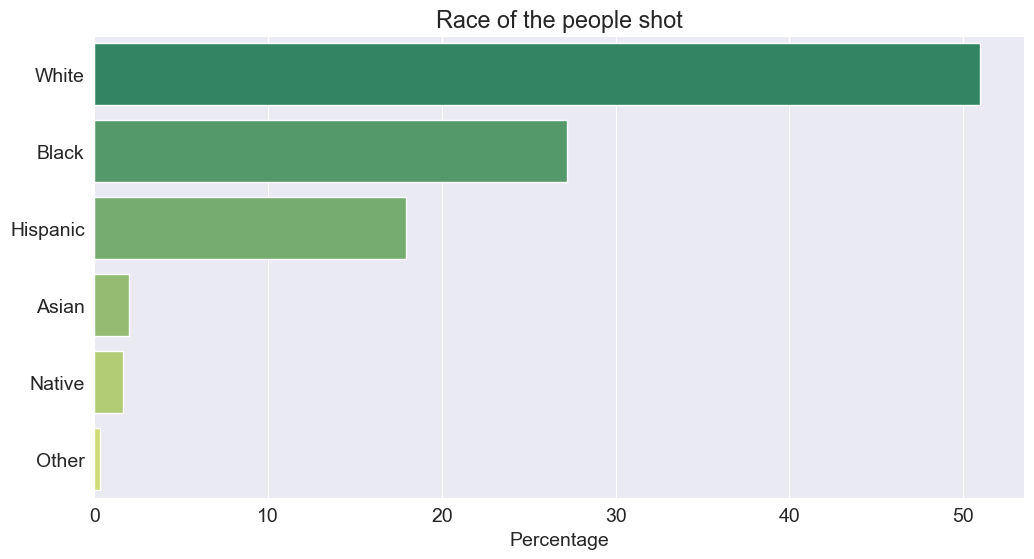

In [83]:
plt.figure(figsize=(12,6))
sns.barplot(x=race_pct, y=race_pct.index, palette='summer')

plt.title('Race of the people shot')
plt.ylabel(None)
plt.xlabel('Percentage');

- Over 50 % of the people killed were White. 26 % of the people were Black, followed by Hispanic at about 18 %.
- 26 % is still higher when we look at the fact that Black people make only about 13 % of US population. But when you take into consideration the role that the black population plays in, not just murder, but crime in general, it explains the disproportion.
- According to the [FBI](https://www.ojjdp.gov/ojstatbb/ezashr/asp/off_selection.asp), African Americans accounted for 52.4% of all homicide offenders in 2018.

Let's now look at the killings by race for each year.

In [84]:
race_df = df.groupby(['year', 'race']).agg('count')['name'].to_frame(name='count').reset_index()
race_df = race_df.sort_values(by='count', ascending=False)
race_df

,year,race,count
5,2015,White,480
34,2020,White,453
22,2018,White,447
11,2016,White,436
17,2017,White,426
28,2019,White,421
39,2021,White,303
24,2019,Black,251
1,2015,Black,240
30,2020,Black,239


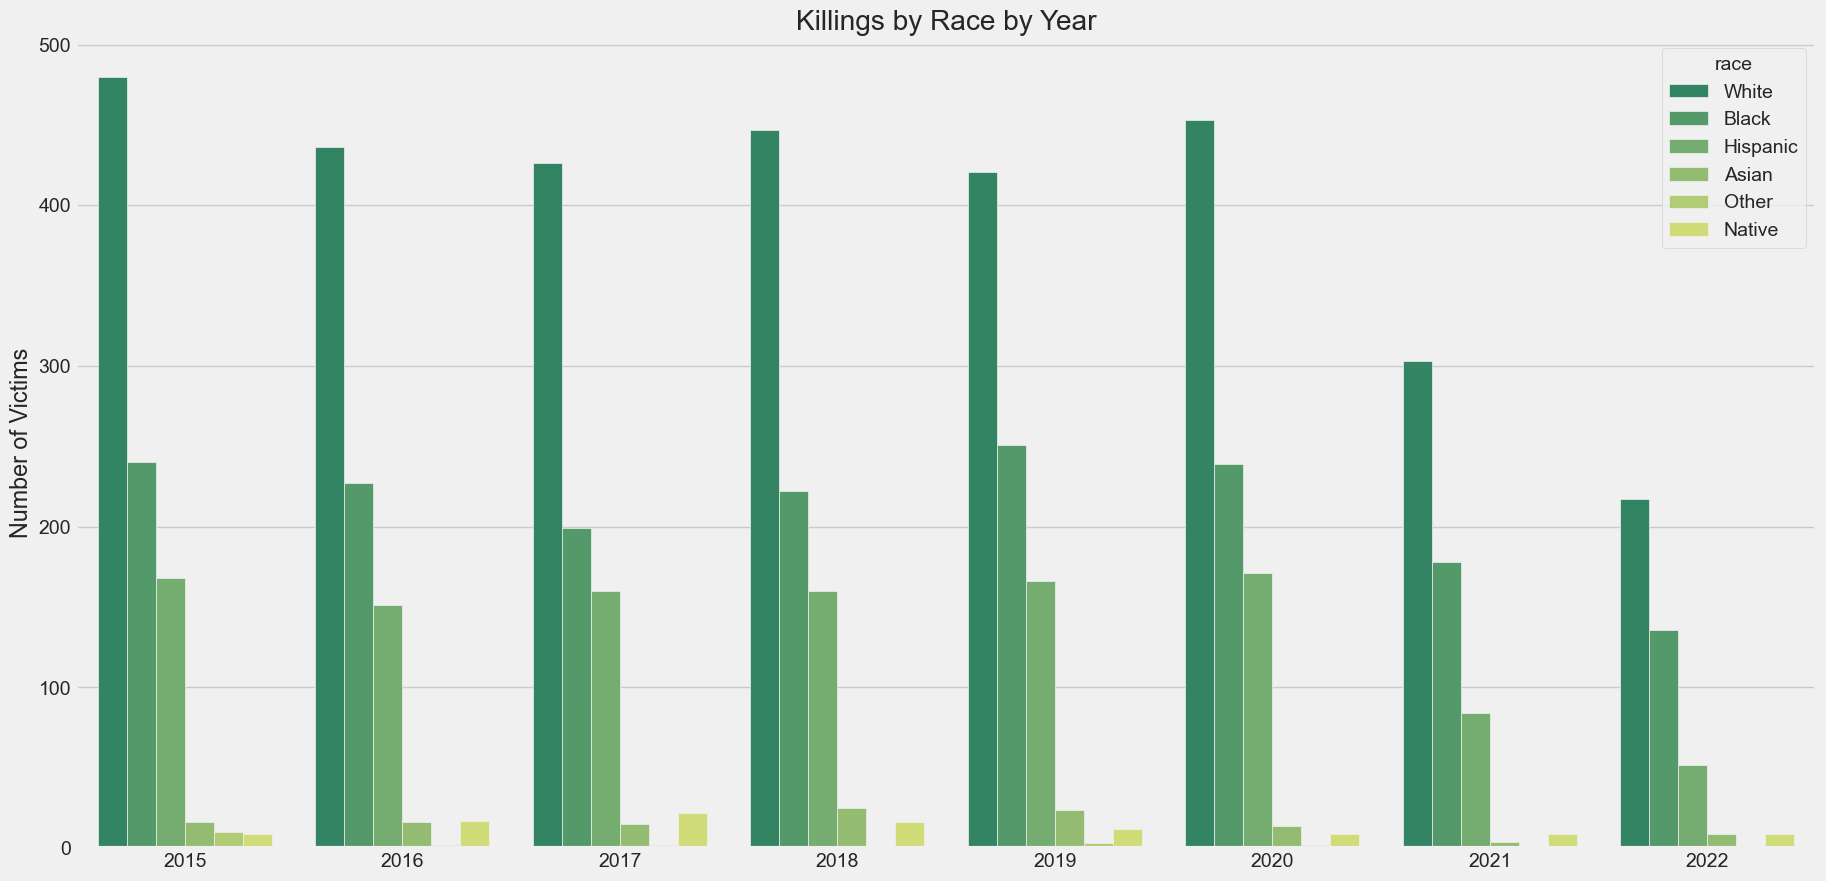

In [85]:
plt.style.use('fivethirtyeight')
plt.figure(figsize=(20,10))
sns.barplot(x="year", y="count",hue="race", data=race_df, palette='summer')
plt.title('Killings by Race by Year')
plt.ylabel('Number of Victims')
plt.xlabel('')
plt.show();

Even when we look at the killings by year, we see that the count of White people killed is much larger than other races each year, followed by Black and Hispanic.

But I'm concerned about the people who were unarmed and not fleeing. So, let's look at those who were unarmed and not fleeing based on race.

For this, we need to create a new dataframe of the rows where value of armed is `unarmed` and that of flee is `Not fleeing`.

In [86]:
race_df = df[df['armed']=='unarmed']
race_df = race_df[race_df['flee']=='Not fleeing']
race_df.shape

(219, 17)

There were 188 cases where the person killed didn't have any arms and didn't try to flee. Let's look at percentage based on race.

In [87]:
race_df = race_df.race.value_counts() * 100 / race_df.race.count()
race_df

race
White       47.488584
Black       29.680365
Hispanic    18.264840
Other        1.826484
Asian        1.826484
Native       0.913242
Name: count, dtype: float64

/var/folders/sp/8dqfb3vn0bq_mrwp93cz6bjw0000gn/T/ipykernel_36057/3035840423.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=race_df, y=race_df.index, palette='summer')


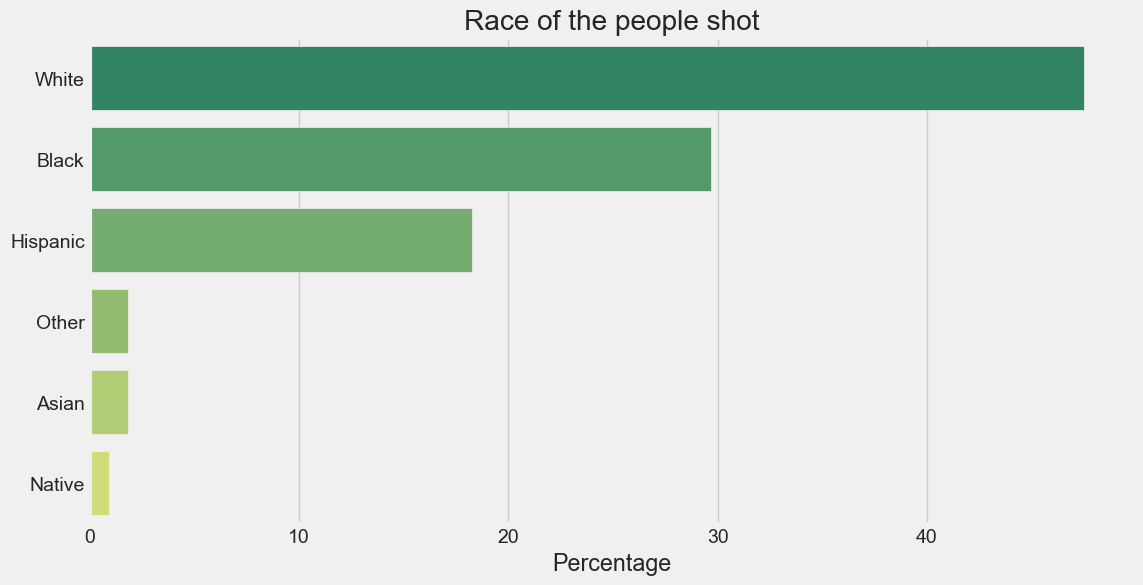

In [88]:
plt.figure(figsize=(12,6))
sns.barplot(x=race_df, y=race_df.index, palette='summer')

plt.title('Race of the people shot')
plt.ylabel(None)
plt.xlabel('Percentage');

This is not much different from the plots we have seen earlier. About 50 % are White, followed by Black and Hispanic.

I think we can conclude that race is not a major contributing factor in the police killings. I'm not saying that there aren't any racist cops but still our analysis till now doesn't reflect upon any systemic racism in the police department.

#### Q2: How much of a factor is age in the police shootings?
For this, we can look at some statistics regarding age first.

In [89]:
df.age.describe()

count    6152.000000
mean       36.890930
std        12.683982
min         6.000000
25%        27.000000
50%        35.000000
75%        45.000000
max        91.000000
Name: age, dtype: float64

Let's visualize the age with the help of a histogram and a violinplot. We can plot multiple charts in a grid using `add_subplot`.

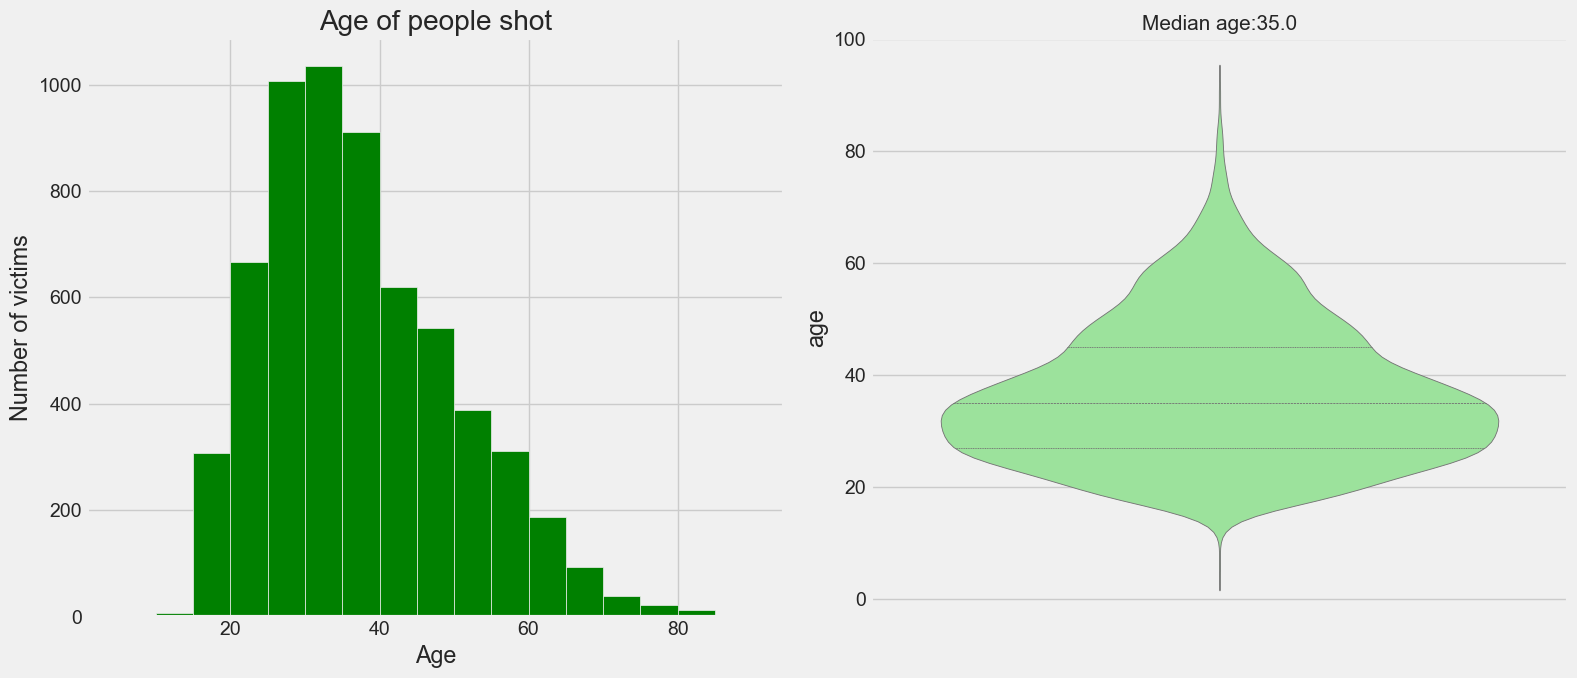

In [100]:
fig = plt.figure(figsize=(16, 7))
ax1 = fig.add_subplot(121)
ax1.set_title('Age of people shot')
ax1.set_xlabel('Age')
ax1.set_ylabel('Number of victims')
ax1.hist(df.age, bins = np.arange(5,95,5), color = 'green');

ax2=fig.add_subplot(122)
# sns.violinplot(y=df['age'],inner='quartile',palette='summer',orient='v')
sns.violinplot(y=df['age'], inner='quartile', color='lightgreen')
ax2.set_title('Median age:{}'.format(df['age'].median()),size=15);

plt.tight_layout()

**Observations:**
- The average age of people killed is 36.73
- The standard deviation is 12.8
- The median age is 35.
- Most of the people were of the age between 20 and 40.
- The histogram is right skewed which tells us that more elders are being killed.

#### Age Distribution by Race
Let's now visualize the distribution of age of different races using a boxplot.

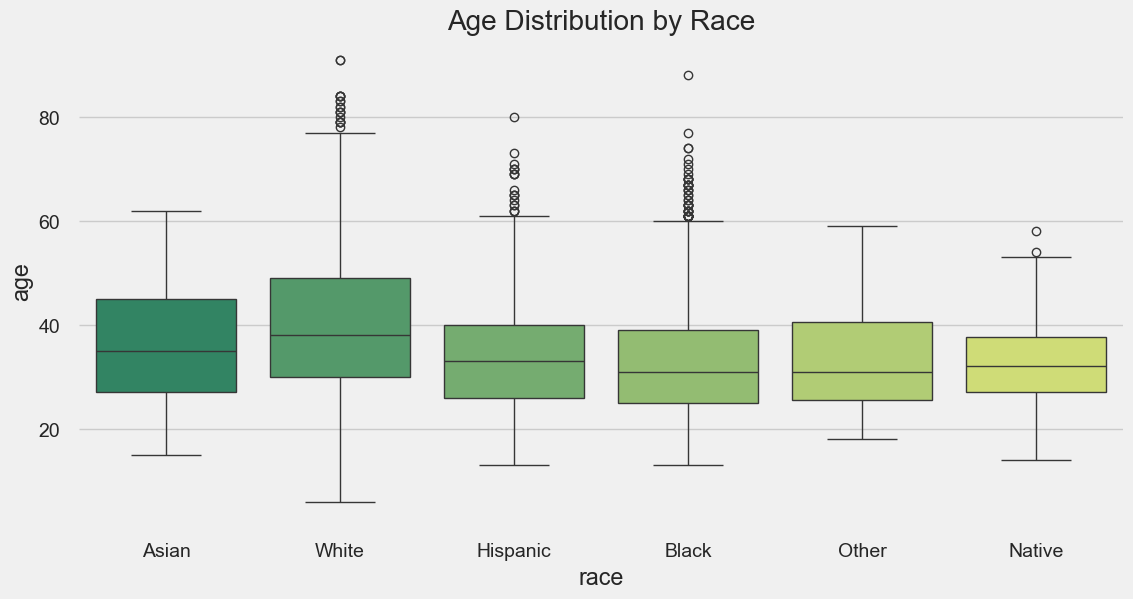

In [102]:
plt.figure(figsize=(12,6))
plt.title('Age Distribution by Race')
# sns.boxplot(x='race', y='age', palette='summer', data=df)
sns.boxplot(
    x='race',
    y='age',
    data=df,
    hue='race',
    palette='summer',
    legend=False
)
sns.despine(offset=10, trim=True)

We can see that the general median age of White is greatest, followed by Asian. But there isn't any drastic difference in the median ages.

Let's also see a stripplot of age by race.

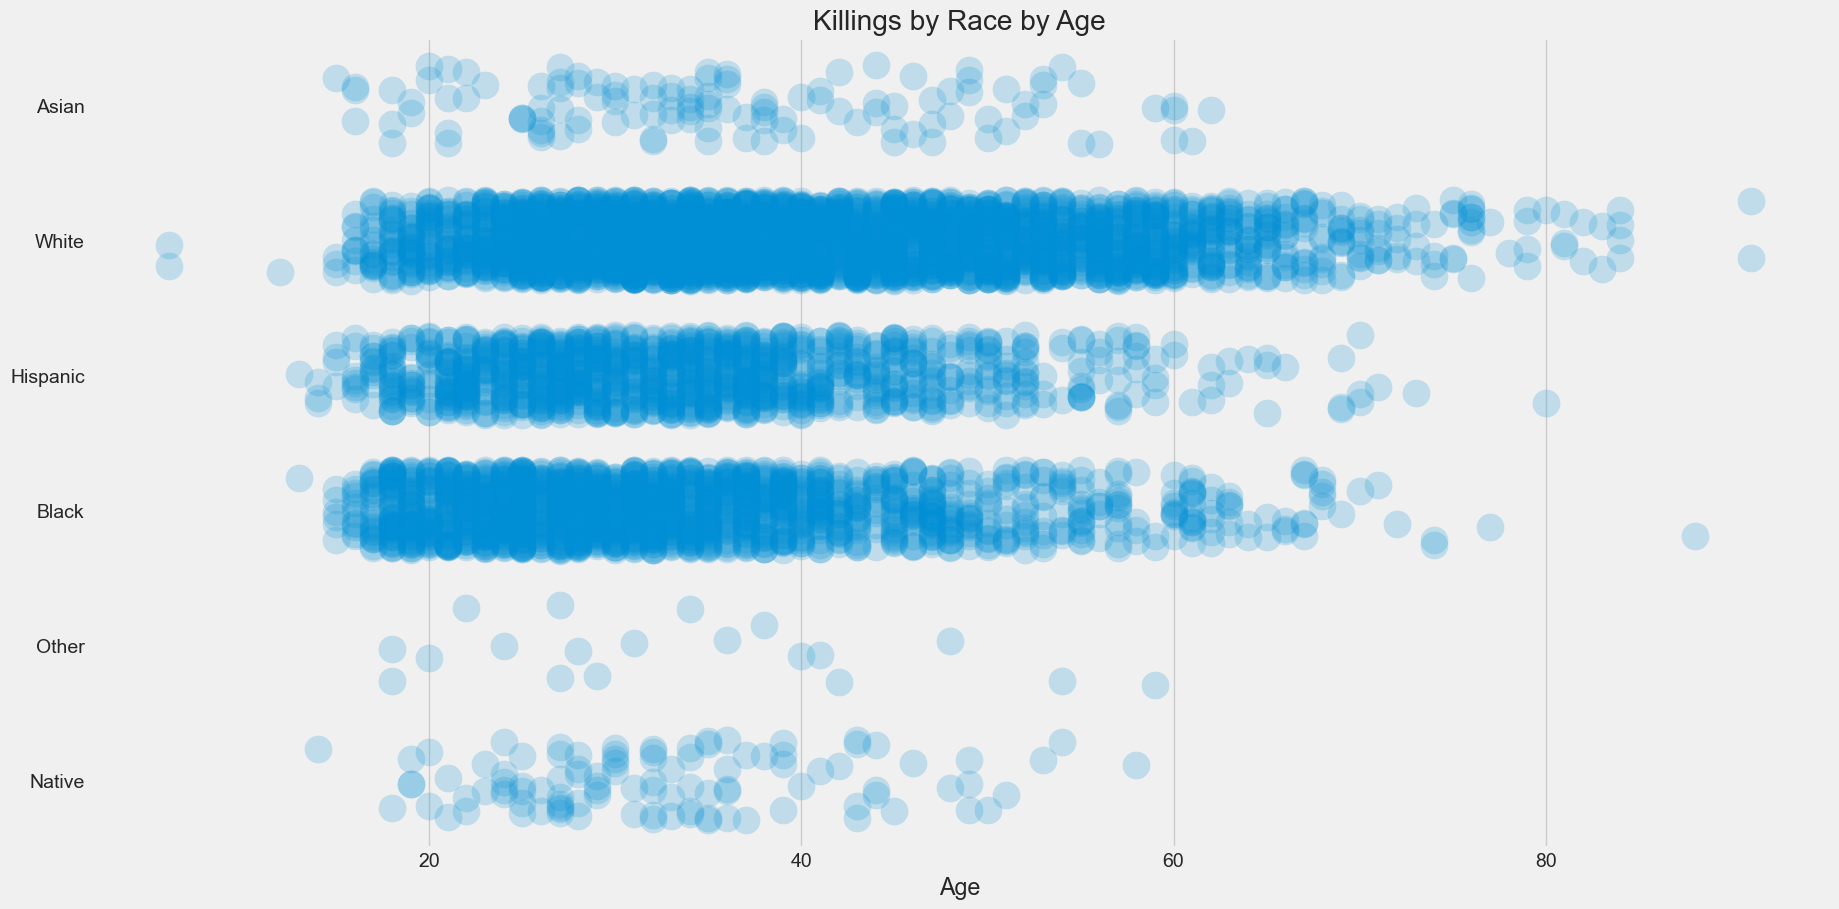

In [103]:
plt.style.use('fivethirtyeight')
fig_dims = (20, 10)
fig, ax = plt.subplots(figsize=fig_dims)
sns.stripplot(
    data=df, x="age", y="race",s=20,
    alpha=0.20,jitter=0.30
)
plt.title('Killings by Race by Age')
plt.ylabel('')
plt.xlabel('Age')
plt.show()

- We can see that in Native, Other and Asian, the age primarily lies in range 20-60
- The cases of age above 60 years were mostly of white people.

#### Age Groups
Let's divide the ages into different groups using `cut` method.

In [104]:
#feature engineering (Adding col Age Group)
bins = [0,17,45,60,100]
group_names = ['Teenager','Adult','Old','Very Old']
df['Age Group'] = pd.cut(df['age'], bins, labels= group_names)

In [105]:
df.head()

,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera,arms_category,year,month,month_num,Age Group
0,Tim Elliot,2015-01-02,shot,gun,53.0,M,Asian,Shelton,WA,True,attack,Not fleeing,False,Guns,2015,January,1,Old
1,Lewis Lee Lembke,2015-01-02,shot,gun,47.0,M,White,Aloha,OR,False,attack,Not fleeing,False,Guns,2015,January,1,Old
2,John Paul Quintero,2015-01-03,shot and Tasered,unarmed,23.0,M,Hispanic,Wichita,KS,False,other,Not fleeing,False,Unarmed,2015,January,1,Adult
3,Matthew Hoffman,2015-01-04,shot,toy weapon,32.0,M,White,San Francisco,CA,True,attack,Not fleeing,False,Other,2015,January,1,Adult
4,Michael Rodriguez,2015-01-04,shot,nail gun,39.0,M,Hispanic,Evans,CO,False,attack,Not fleeing,False,Piercing Objects,2015,January,1,Adult


In [106]:
age_df =df.groupby(['Age Group']).agg('count')['age'].to_frame(name='count').reset_index()
age_df=age_df.sort_values(by=['count'],ascending=False)
age_df

,Age Group,count
1,Adult,4573
2,Old,1162
3,Very Old,307
0,Teenager,110


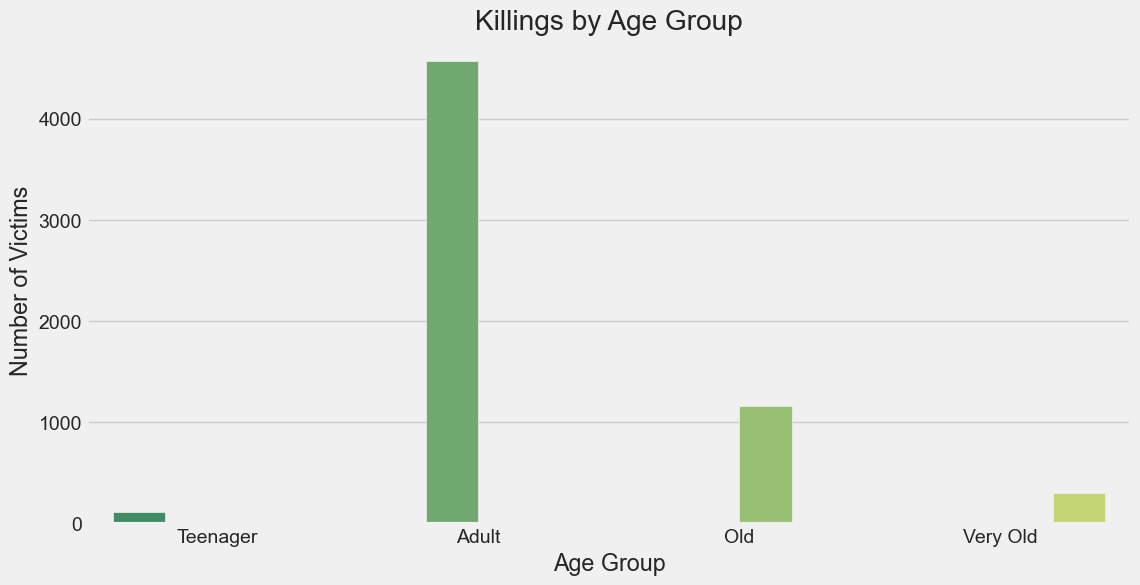

In [108]:
plt.style.use('fivethirtyeight')
plt.figure(figsize=(12,6))
# sns.barplot(x='Age Group', y='count', data=age_df, palette='summer')
sns.barplot(
    data=age_df,
    x='Age Group',
    y='count',
    hue='Age Group',
    palette='summer',
    legend=False
)
plt.title('Killings by Age Group')
plt.ylabel('Number of Victims')
plt.show();

Most people belong to Adult Category, let's take a closer look at the `Teenager` category.

In [109]:
teens = df[df['Age Group'] == 'Teenager']
teens.sort_values('age').head(15)

,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera,arms_category,year,month,month_num,Age Group
2590,Kameron Prescott,2017-12-21,shot,unarmed,6.0,M,White,Schertz,TX,False,other,Not fleeing,False,Unarmed,2017,December,12,Teenager
779,Jeremy Mardis,2015-11-03,shot,unarmed,6.0,M,White,Marksville,LA,False,other,Car,True,Unarmed,2015,November,11,Teenager
944,Ciara Meyer,2016-01-11,shot,unarmed,12.0,F,White,Penn Township,PA,False,other,Not fleeing,False,Unarmed,2016,January,1,Teenager
5471,Adam Toledo,2021-03-29,shot,unknown,13.0,M,Hispanic,Chicago,IL,False,other,Foot,True,Unknown,2021,March,3,Teenager
1551,Tyre King,2016-09-14,shot,toy weapon,13.0,M,Black,Columbus,OH,False,other,Foot,False,Other,2016,September,9,Teenager
3527,Antonio Arce,2019-01-15,shot,toy weapon,14.0,M,Hispanic,Tempe,AZ,False,other,Foot,True,Other,2019,January,1,Teenager
1468,Jesse James Romero,2016-08-09,shot,gun,14.0,M,Hispanic,Los Angeles,CA,False,attack,Foot,True,Guns,2016,August,8,Teenager
2519,Jason Ike Pero,2017-11-08,shot,knife,14.0,M,Native,Odanah,WI,False,other,Not fleeing,False,Sharp Objects,2017,November,11,Teenager
5837,Valentina Orellana-Peralta,2021-12-23,shot,unarmed,14.0,F,Hispanic,Los Angeles,CA,False,other,Foot,True,Unarmed,2021,December,12,Teenager
2076,Jacob Peterson,2017-05-06,shot,toy weapon,15.0,M,White,San Diego,CA,True,attack,Not fleeing,True,Other,2017,May,5,Teenager


**Observation:**
- 2 six year old unarmed kids were killed which clearly indicates police brutality.
- In many cases, the children had `toy weapon`, probably a toy gun which might have seemed like a real gun. But still the cops should've handled the situation better instead of killing children.
- We can see cases where the children had real guns, let's look at this point in detail.

In [110]:
teens_with_gun = teens[teens['armed'] == 'gun']
teens_with_gun.shape[0]

51

Out of 94 cases in which teens were killed, 45(about half) possessed a gun. Federal law prohibits the possession of a handgun or handgun ammunition by any person under the age of 18. They must have acquired it illegally.

**Conclusion:**
- The average age of the people killed was 36.73
- Most of the people belonged to `Adult` category.
- In about 2% of the cases, teenagers were killed.
- We don't see much correlation between the age and the killings.

#### Q3: Are the shootings proof of police brutality? Or did the cops shoot in self defense?
Let's first look at the percentage of people based on whether they tried to flee or not.

In [114]:
# flee_df = df.flee.value_counts().reset_index().rename(columns={'index':'flee', 'flee':'count'})
flee_df = (
    df['flee']
      .value_counts()
      .rename_axis('flee')
      .reset_index(name='count')
)
flee_df

,flee,count
0,Not fleeing,3714
1,Car,904
2,Foot,859
3,Other,242


Let's look this information in a pie-chart.

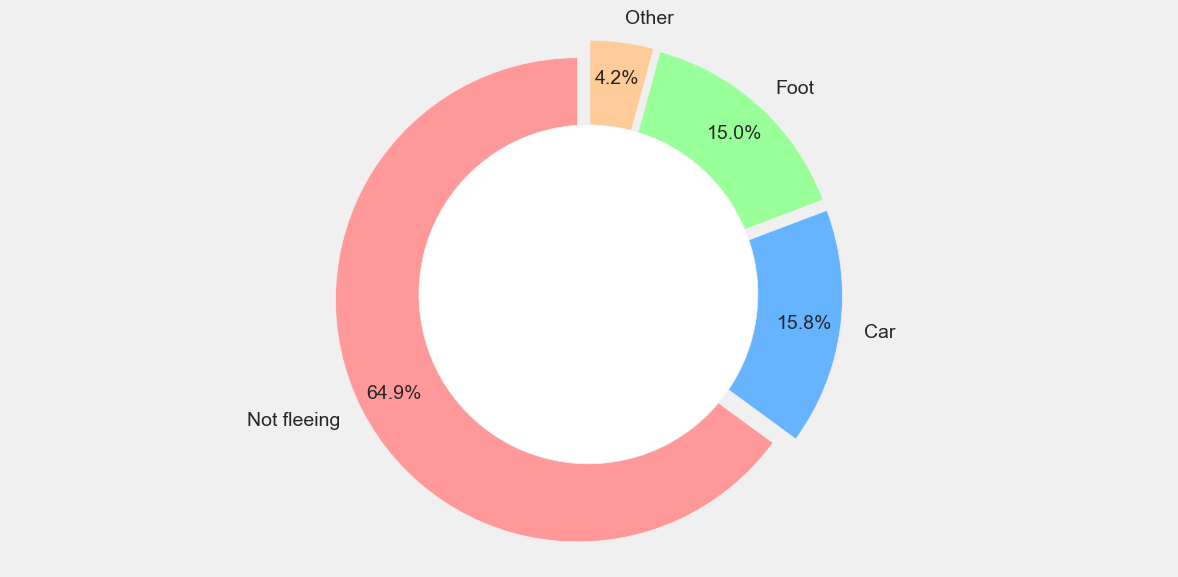

In [115]:
#colors
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99']
#explsion
explode = (0.05,0.05,0.05,0.05)

plt.figure(figsize=(12,6))
plt.pie(flee_df['count'], labels=flee_df['flee'], colors = colors, autopct='%1.1f%%', startangle=90, pctdistance=0.85, explode = explode)
#draw circle
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
# Equal aspect ratio ensures that pie is drawn as a circle
plt.axis('equal')  
plt.tight_layout()
plt.show();

**Observation:**

- 67% of victimes didn't try to flee yet they were killed.This is completely an unexpected scenario.
- Only 15% of people tried to flee by car and 14.4% tried to flee by foot.

**Armed or Not**

Let's now look at the arms used by the people.

In [116]:
armed = df.armed.dropna().unique()
print('Total Number of Unique Arms Used: {}'.format(len(armed)))

Total Number of Unique Arms Used: 99


In [120]:
# armed_df = df.armed.value_counts().reset_index().rename(columns={'index':'weapons used','armed':'count'})
armed_df = (
    df['armed']
      .value_counts()
      .rename_axis('weapons used')
      .reset_index(name='count')
)

Let's make a barplot of the 10 most used arms.

In [121]:
armed_df.head(10)

,weapons used,count
0,gun,3700
1,knife,936
2,unarmed,431
3,unknown,286
4,toy weapon,221
5,vehicle,213
6,machete,53
7,Taser,32
8,ax,25
9,sword,23


<Axes: title={'center': 'Weapons Used'}, xlabel='weapons used', ylabel='count'>

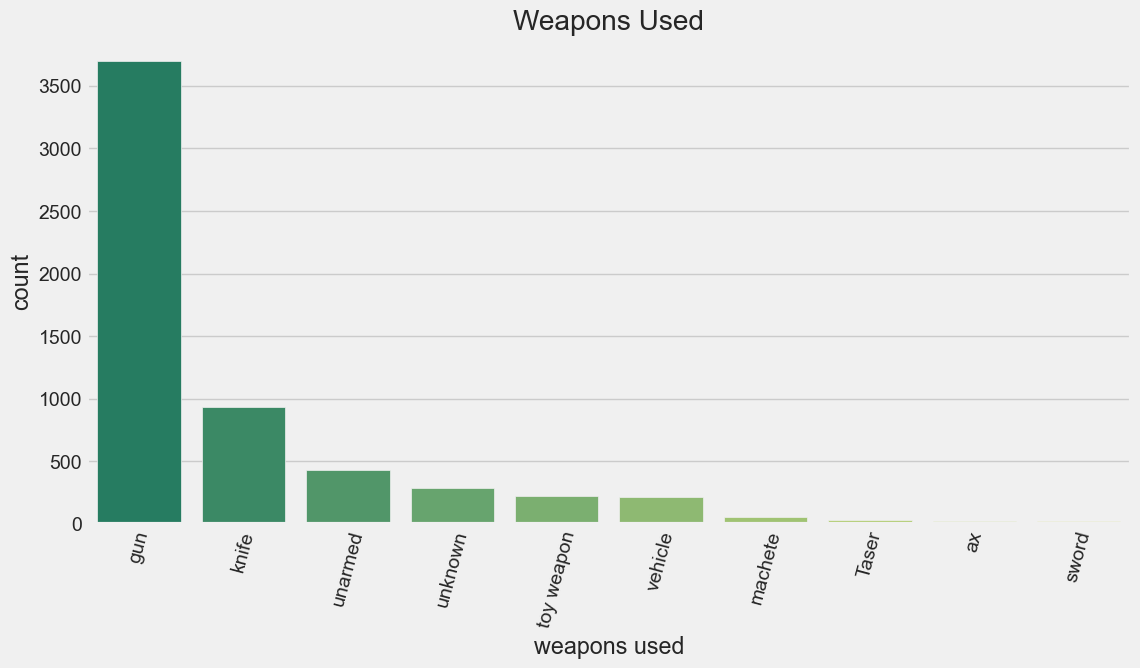

In [128]:
plt.figure(figsize=(12,6))
plt.title('Weapons Used')
plt.xticks(rotation=75)
# sns.barplot(x=armed_df['weapons used'].head(10), y=armed_df['count'], palette='summer');
top10 = armed_df.head(10)
sns.barplot(
    data=top10,
    x='weapons used',
    y='count',
    hue='weapons used',
    palette='summer',
    legend=False
)

We can see clearly that majority people had gun, probably becaause of the lenient Arms laws in the US. It was followed by knife and unarmed. In 352 cases, the person killed was unarmed.

**Threat Level**

Let's now look at the column `threat_level` to get more insights.

In [129]:
threat_df = df.threat_level.value_counts()
threat_df

threat_level
attack          4025
other           2043
undetermined     217
Name: count, dtype: int64

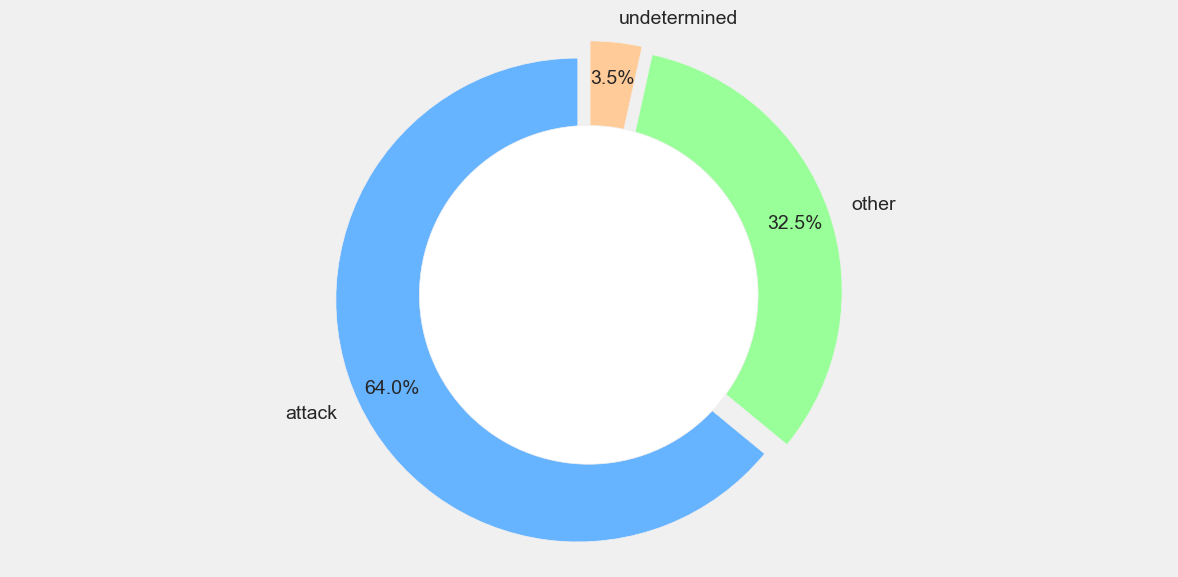

In [130]:
#colors
colors = ['#66b3ff','#99ff99','#ffcc99']
#explsion
explode = (0.05,0.05,0.05)

plt.figure(figsize=(12,6))
plt.pie(threat_df, labels=threat_df.index, colors = colors, autopct='%1.1f%%', startangle=90, pctdistance=0.85, explode = explode)
#draw circle
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
# Equal aspect ratio ensures that pie is drawn as a circle
plt.axis('equal')  
plt.tight_layout()
plt.show()

**From the ReadMe**

The general criteria for the attack label was that there was the most direct and immediate threat to life. That would include incidents where officers or others were shot at, threatened with a gun, attacked with other weapons or physical force, etc. The attack category is meant to flag the highest level of threat. The other and undetermined categories represent all remaining cases. Other includes many incidents where officers or others faced significant threats.

Let's see how many people's threat_level is `attack` and were `unarmed`.

In [131]:
unarmed_attack = df[df['threat_level'] == 'attack']
unarmed_attack = unarmed_attack[unarmed_attack['armed'] == 'unarmed']

In [132]:
print('{} people were unarmed and attacking.'.format(len(unarmed_attack)))

167 people were unarmed and attacking.


We can see, out of 352 unarmed people, 136 were attacking.

**Threat Level based on race**

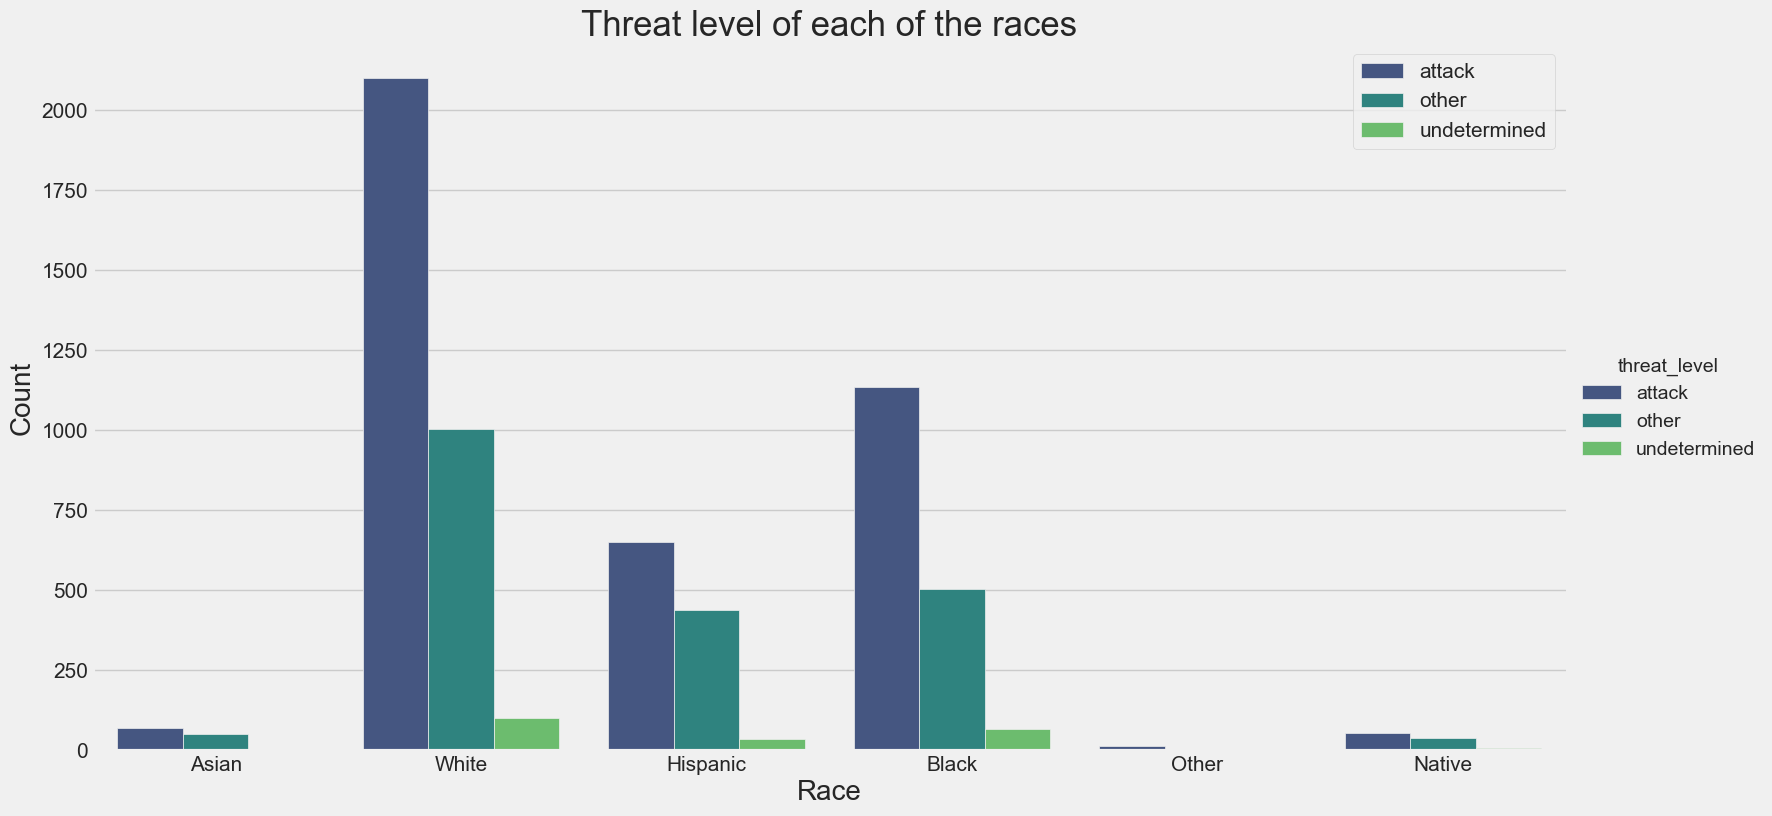

In [133]:
sns.catplot(x='race',kind='count',data=df,hue='threat_level',palette='viridis',height=8,aspect=2)
plt.xticks(size=15)
plt.xlabel('Race',size=20)
plt.yticks(size=15)
plt.ylabel('Count',size=20)
plt.title('Threat level of each of the races',size=25)
plt.legend(fontsize=15);

From the above plot, we can see that the threat level was highly dangerous for the whites and hence, had to be shot down. The blacks had a high threat level as well but overall, it was lower than the whites.

**Conclusion:**
- Most of the people killed were attacking and/or trying to flee.
- Most of the people had a gun or a knife.
- About 3-4% of the people killed were unarmed and not attacking.
This shows that most of the shootings were done in self defense. But there were cases where the cops behaved brutally and unjustly.

#### Q4: Did the cops have body cams? Did body cams play any role in the shootings?
Police violence has become a high-profile topic in recent months due to the death of George Flyod. A wave of anti-racism protests swept across the United States, but just ... why exactly after this incident? Undoubtedly, a very important role was played by the fact that the whole dramatic situation of George Floyd's murder was recorded, and the video of this incident quickly circulated the internet. So, it's important to look at the role of body cams in the shootings.

In [134]:
body_cam = df.body_camera.value_counts()
body_cam

body_camera
False    5362
True      923
Name: count, dtype: int64

Let's look at the number of killings each year based on whether the cops had body cam or not.

In [137]:
# no_cam = df[df['body_camera'] == False].year.value_counts()
# cam = df[df['body_camera'] == True].year.value_counts()
# no_cam = no_cam.to_frame().reset_index().rename(columns={'index':'year', 'year':'count'}).sort_values(by='year')
# cam = cam.to_frame().reset_index().rename(columns={'index':'year', 'year':'count'}).sort_values(by='year')

no_cam = (
    df[df['body_camera'] == False]['year']
      .value_counts()
      .rename_axis('year')
      .reset_index(name='count')
      .sort_values(by='year')
)

cam = (
    df[df['body_camera'] == True]['year']
      .value_counts()
      .rename_axis('year')
      .reset_index(name='count')
      .sort_values(by='year')
)

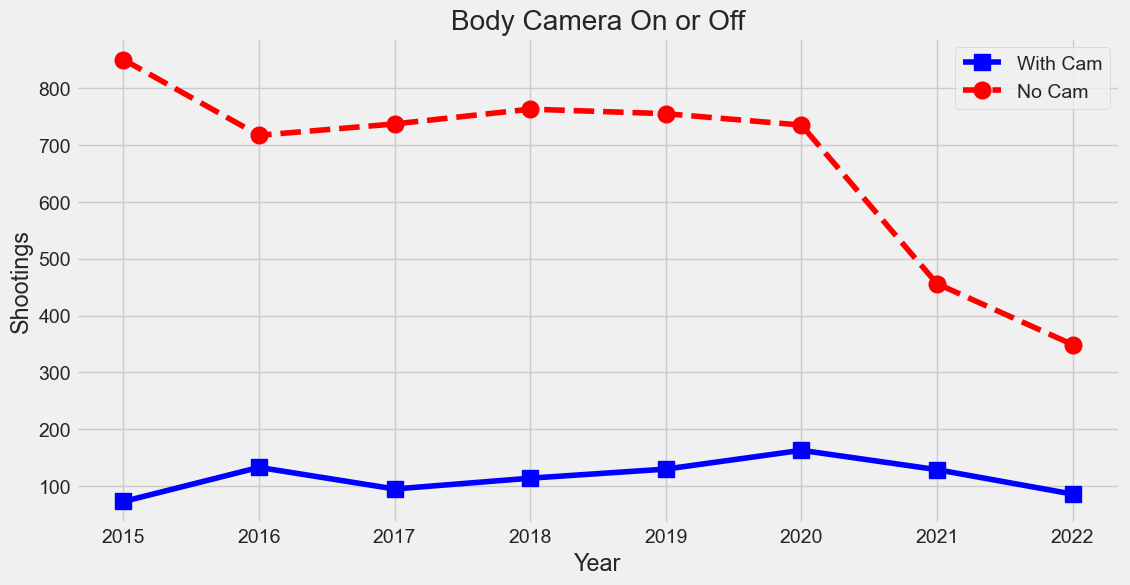

In [138]:
plt.figure(figsize=(12,6))
plt.plot(cam['year'], cam['count'], 's-b', linewidth=4, markersize=12)
plt.plot(no_cam['year'], no_cam['count'], 'o--r', linewidth=4, markersize=12,)

plt.xlabel('Year')
plt.ylabel('Shootings')

plt.title('Body Camera On or Off')
plt.legend(['With Cam', 'No Cam']);

We can see, each year the number of killings without body cams is much higher than those with cams.

**Based on Race**

In [139]:
race_df =df.groupby(['race','body_camera']).agg('count')['name'].to_frame(name='count').reset_index()
race_df=race_df.sort_values(by=['count'],ascending=False)

In [140]:
race_df = df.groupby(['race', 'body_camera']).size().reset_index().pivot(columns='body_camera', index='race', values=0)
race_df

body_camera,False,True
race,,
Asian,99,25
Black,1363,345
Hispanic,958,168
Native,87,17
Other,17,2
White,2838,366


Let's see this information on log scale.

<Figure size 1200x600 with 0 Axes>

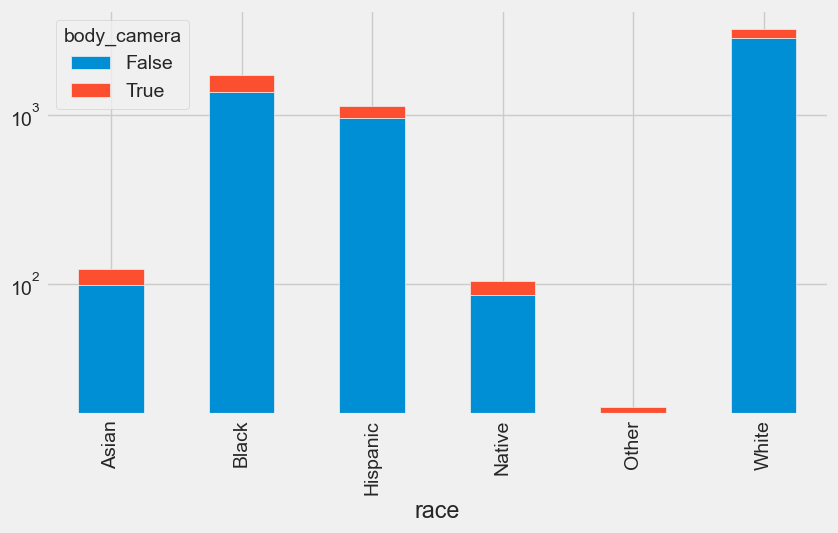

In [141]:
plt.figure(figsize=(12,6))
race_df.plot(kind='bar', stacked=True, log=True);

Let's also look at the percentages of shootings with cam or not for each race.

In [148]:
# race_copy = race_df.copy()
# for row, col in race_copy.iterrows():
#     sum = col.loc[False] + col.loc[True]
#     x = col.loc[False] * 100 / sum
#     y = col.loc[True] * 100 / sum
#     race_copy.at[row, False] = x
#     race_copy.at[row, True] = y

race_copy = race_df.div(race_df.sum(axis=1), axis=0) * 100

<Figure size 1200x600 with 0 Axes>

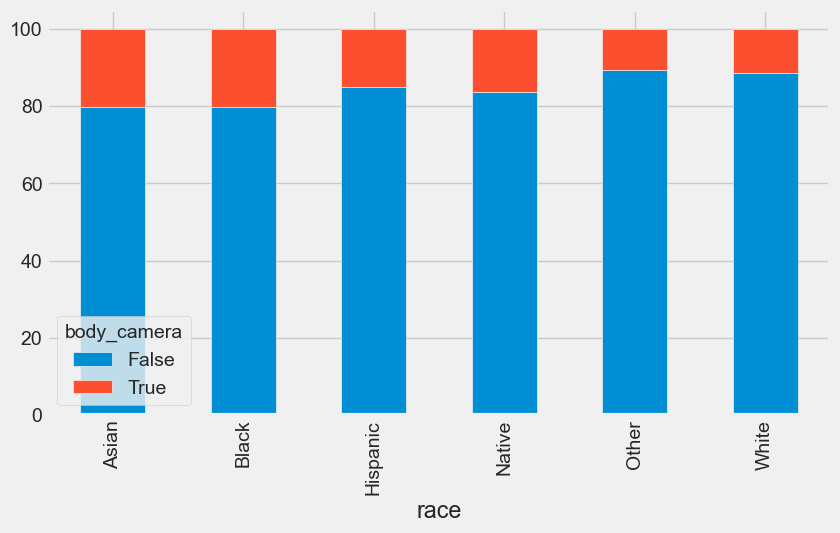

In [149]:
plt.figure(figsize=(12,6))
race_copy.plot(kind='bar', stacked=True);

It turns out that the most frequently recorded were attacks on Asians and Blacks (about 16%) and least often on the white race (only 10%). The differences are not too big, so it's hard to find dependencies.

We can conclude that having body cams may have effect on the conduct of the cops. In most of the shootings, cops didn't wear cams. Maybe the outcome would've been different if they were made to wear cams. I searched for some articles regarding this topic, it's a [debated topic.](https://www.pewtrusts.org/en/research-and-analysis/blogs/stateline/2020/01/14/body-cameras-may-not-be-the-easy-answer-everyone-was-looking-for)

#### Q5: Which states and cities had the most shootings?
Let's find out which states and cities of US had the most shootings.

**Most suffered State**

In [152]:
# shoot_state=df['state'].value_counts().to_frame().reset_index().rename(columns={'index':'state','state':'count'}).sort_values(by='count',ascending=False)
# shoot_state.head(5)

shoot_state = (
    df['state']
      .value_counts()
      .rename_axis('state')
      .reset_index(name='count')
      .sort_values(by='count', ascending=False)
)

shoot_state.head(5)

,state,count
0,CA,874
1,TX,572
2,FL,428
3,AZ,268
4,GA,226


In [153]:
print("Average number of victims per state is {}.".format(round(shoot_state['count'].mean())))

Average number of victims per state is 123.


Let's visualize the top 10 states in a bar plot.

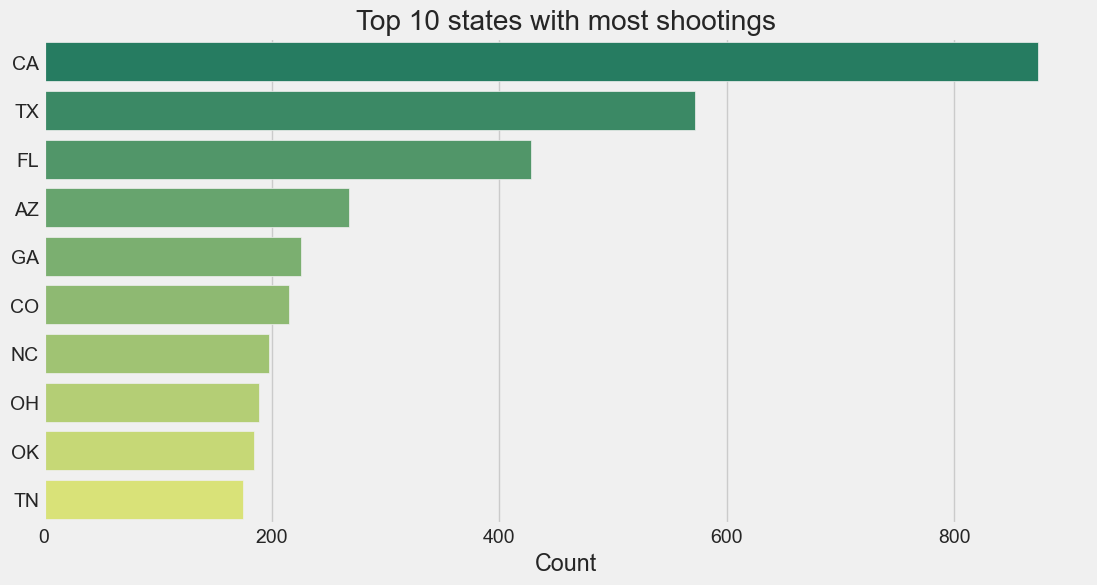

In [157]:
plt.figure(figsize=(12,6))
shoot_state = shoot_state.head(10)
# sns.barplot(x=shoot_state['count'], y=shoot_state['state'], palette='summer')
sns.barplot(
    data=shoot_state,
    x='count',
    y='state',
    hue='state',
    palette='summer',
    legend=False
)

plt.title('Top 10 states with most shootings')
plt.ylabel(None)
plt.xlabel('Count');

**Observation:**

- California has recorded most number of victims.
- Texas and Florida are next to California. These three are densely populated states in US.
- Average number of victims per state is 96.
- Densely populated state are the most victim faced state.

**Most suffered City**

In [159]:
# shoot_city=df['city'].value_counts().to_frame().reset_index().rename(columns={'index':'city','city':'count'}).sort_values(by='count',ascending=False)
shoot_city = (
    df['city']
      .value_counts()
      .rename_axis('city')
      .reset_index(name='count')
      .sort_values(by='count', ascending=False)
)

In [160]:
shoot_city.head(10)

,city,count
0,Los Angeles,114
1,Phoenix,80
2,Houston,67
3,San Antonio,59
4,Las Vegas,52
5,Chicago,45
6,Jacksonville,43
7,Columbus,42
8,Albuquerque,39
9,Kansas City,39


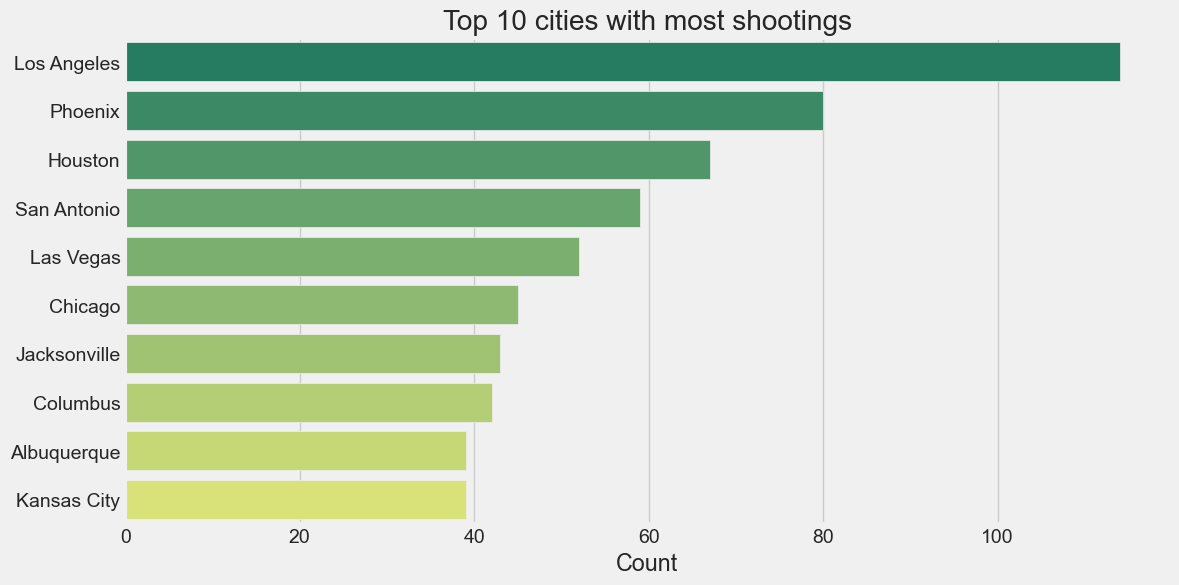

In [163]:
plt.figure(figsize=(12,6))
shoot_city = shoot_city.head(10)
# sns.barplot(x=shoot_city['count'], y=shoot_city['city'], palette='summer')
sns.barplot(
    data=shoot_city,
    x='count',
    y='city',
    hue='city',
    palette='summer',
    legend=False
)

plt.title('Top 10 cities with most shootings')
plt.ylabel(None)
plt.xlabel('Count');

**Observation:**

- Los Angeles,Phoenix and Houston have recorded most victims.

## Inferences and Conclusion 
We've drawn many interesting inferences from the dataset, here's a summary of few of them along with the conclusions we've reached after analyzing the shootings in US:
- On average, 864 people are killed each year and 70 people each month.


- Most of the people killed by the police were White. This is contrary to the popular belief and the media hype that the police target and kill the Black people disproportionately because of racism.


- 26% of the people killed were Black, this seems disproportionate if we look at the fact that Black people only make about 13% of US population. But when you take into consideration the role that the black population plays in, not just murder, but crime in general, it explains this disproportion.


- Over 95% of the people killed were males. This was expected as females commit less crimes comparative to males.


- Most of the people killed were adults. The average age of the people shot is 36.73


- About 2% of the people killed were teenagers, half of them had a gun, which they must have acquired illegally.


- In most of the cases, the cops didn't have a body cam. Maybe if they were made to wear a cam, they would've behaved differently.


- California and Texas had the most number of shootings. They are densely populated states in US.


- Vast majority of the people had gun and/or knife. Most of the people were attacking and/or trying to flee. This shows that most of the shootings were done in self defense.


- A significant number of people were unarmed and not attacking. Even 6 year olds were killed who were unarmed and couldn't harm the cops. Thus, we can say that there are definitely some cops who abuse their powers and don't respect the civil rights of the people. These cops must face the consequences for their actions.


**[Qualified Immunity](https://en.wikipedia.org/wiki/Qualified_immunity#:~:text=In%20the%20United%20States%2C%20qualified,reasonable%20person%20would%20have%20known%22.)** is the legal provision in US which has become a nearly failsafe tool to let police brutality go unpunished and deny victims their constitutional rights. It is important to repeal qualified immunity so that the bad cops can be punished for their actions. This is the most crucial step that can be taken to end police violence.

## References and Future Work
There's a lot of information to be discovered about the police shootings, and we've barely scratched the surface. Here are some ideas for further exploration:
- Repeat the analysis for different countries and compare the results
- Look at the dataset in more depth in terms of body_cam and gender

References:
- The Washington Post Data: https://github.com/washingtonpost/data-police-shootings
- Pandas user guide: https://pandas.pydata.org/docs/user_guide/index.html
- Matplotlib user guide: https://matplotlib.org/3.3.1/users/index.html
- Seaborn user guide & tutorial: https://seaborn.pydata.org/tutorial.html

## Save and upload your work
Whether you're running this Jupyter notebook on an online service like Binder or on your local machine, it's important to save your work from time, so that you can access it later, or share it online. You can upload this notebook to your [Jovian.ml](jovian.ml) account using the `jovian` Python library.

In [164]:
project_name = "us-police-shootings-final-analysis"

In [165]:
# !pip install jovian --upgrade -q
import jovian

ModuleNotFoundError: No module named 'jovian'

In [ ]:
jovian.commit(project=project_name)

`jovian.commit` uploads the notebook to your [Jovian.ml](jovian.ml) account, captures the Python environment and creates a shareable link for your notebook as shown above. You can use this link to share your work and let anyone (including you) run your notebooks and reproduce your work.